**1. Data Exploration and Preprocessing**

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
gbv = pd.read_csv('data/train_consensus.csv')

In [10]:
gbv.head()

,question_id,question_text,final_labels
0,Question 1,Title: Workplace Sexual Harassment while WFH\n...,no_crisis
1,Question 2,Title: I’m scared\n\nText: I don’t know what t...,domesticviolence_ongoing
2,Question 3,Title: Is my supervisor harassing me?\n\nText:...,sexualharassment_ongoing
3,Question 4,Title: [URGENT] I think a friend committed sui...,no_crisis
4,Question 5,Title: Feel socially incompetent and anxious m...,no_crisis


In [11]:
gbv.shape

(4181, 3)

In [12]:
gbv.info()

<class 'pandas.DataFrame'>
RangeIndex: 4181 entries, 0 to 4180
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   question_id    4181 non-null   str  
 1   question_text  4181 non-null   str  
 2   final_labels   4181 non-null   str  
dtypes: str(3)
memory usage: 98.1 KB


In [13]:
gbv.describe(include="all")

,question_id,question_text,final_labels
count,4181,4181,4181
unique,4181,4179,80
top,Question 1,"Title: A small rant, I guess. Oh, and I love m...",no_crisis
freq,1,2,1160


The training dataset contains 4,181 records and 3 columns: `question_id`, `question_text` and `final_labels`.

All columns contain text data, and no missing values were identified.

The `question_text` column contains the narratives that will be used as input features, while `final_labels` contains the annotated crisis categories that will serve as the target variable.

The `question_id` column is an identifier and will not be used as a predictive feature.

The dataset includes labels such as domestic violence, sexual harassment and no crisis, indicating its potential relevance to the proposed GBV classification task.

In [14]:
# Check for duplicate rows
gbv.duplicated().sum()

np.int64(0)

In [15]:
# Checking for duplicated narratives
gbv['question_text'].duplicated().sum()

np.int64(2)

In [16]:
# Inspecting the duplicate narratives
gbv[gbv.duplicated(subset='question_text', keep=False)]

,question_id,question_text,final_labels
754,Question 755,"Title: A small rant, I guess. Oh, and I love m...",sexualharassment_ongoing
1635,Question 1636,Title: Passively dying\n\nText: Over the last ...,"suicideideation_active_ongoing, selfharm_ongoing"
2156,Question 2157,"Title: A small rant, I guess. Oh, and I love m...",sexualharassment_ongoing
2720,Question 2721,Title: Passively dying\n\nText: Over the last ...,"suicideideation_active_ongoing, selfharm_ongoing"


Since the narratives and labels match, we can safely remove one of each record

In [17]:
gbv = gbv.drop_duplicates(subset=['question_text', 'final_labels']).reset_index(drop=True)

gbv.shape

(4179, 3)

In [18]:
# Exploring the target variable
gbv['final_labels'].value_counts()

final_labels
no_crisis                                                                         1160
selfharm_ongoing                                                                   558
suicideideation_passive_ongoing                                                    438
suicideideation_active_ongoing                                                     365
domesticviolence_past                                                              230
                                                                                  ... 
domesticviolence_ongoing, rape_past                                                  1
sexualharassment_past, rape_past                                                     1
sexualharassment_ongoing, sexualharassment_past                                      1
suicideideation_active_ongoing, childabuse_endangerment_past, selfharm_ongoing       1
suicideideation_active_past, suicideideation_active_ongoing                          1
Name: count, Length: 80, dtype

Some narratives contain multiple labels, indicating that a single report can describe more than one crisis-related experience.

Therefore, further analysis is required to separate the individual labels, examine their distributions and identify the categories relevant to the GBV classification task.

In [19]:
# Separating the multiple labels
labels = gbv['final_labels'].str.split(',').explode().str.strip()

# Count each individual label
label_counts = labels.value_counts()

label_counts

final_labels
no_crisis                          1160
selfharm_ongoing                    702
suicideideation_passive_ongoing     600
suicideideation_active_ongoing      433
rape_past                           352
domesticviolence_past               267
domesticviolence_ongoing            233
sexualharassment_ongoing            218
selfharm_past                       214
sexualharassment_past               156
childabuse_endangerment_past        143
suicideideation_active_past          60
rape_ongoing                         55
childabuse_endangerment_ongoing      39
suicideideation_passive_past         14
Name: count, dtype: int64

In [20]:
labels.nunique()

15

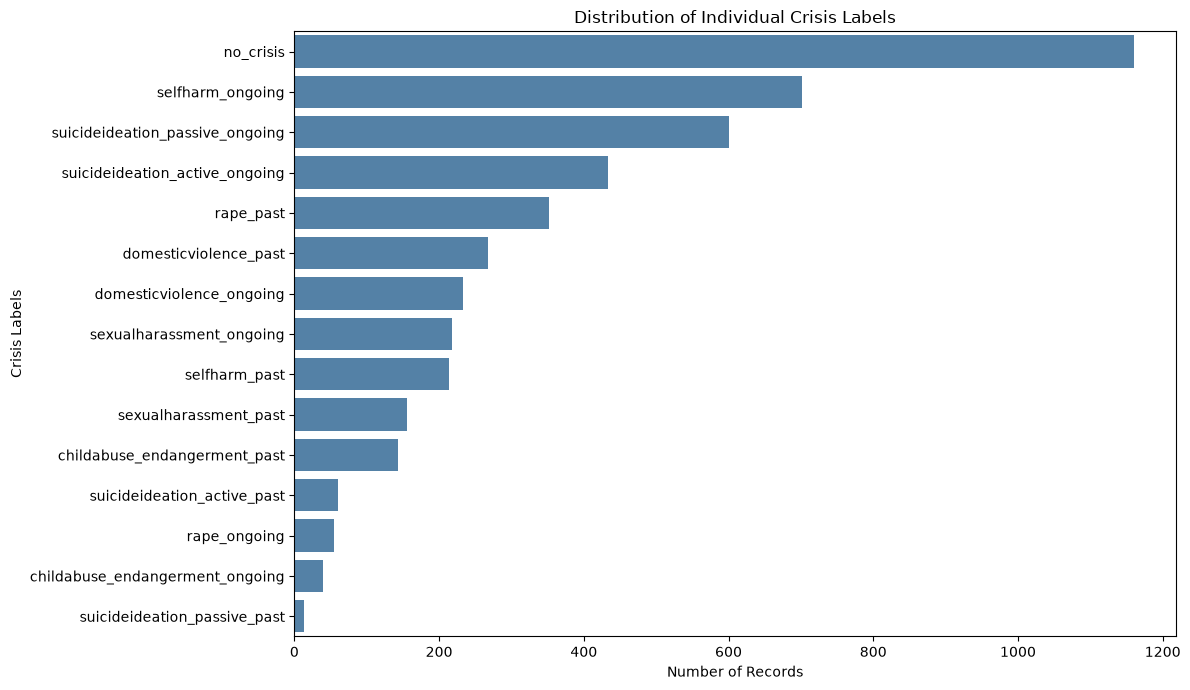

In [21]:
# Visualizing the label distribution
plt.figure(figsize=(12, 7))

sns.barplot(
    x=label_counts.values,
    y=label_counts.index,
    color="steelblue"
)

plt.title("Distribution of Individual Crisis Labels")
plt.xlabel("Number of Records")
plt.ylabel("Crisis Labels")

plt.tight_layout()
plt.show()

In [22]:
# Identifying GBV related records
gbv_categories = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment"
]

gbv_pattern = "|".join(gbv_categories)

gbv_mask = gbv["final_labels"].str.contains(
    gbv_pattern,
    regex=True,
    na=False
)

print("GBV-related records:", gbv_mask.sum())
print("Other records:", (~gbv_mask).sum())

GBV-related records: 1257
Other records: 2922


In [23]:
# Examining the categories individually
gbv_category_counts = {}

for category in gbv_categories:
    count = gbv["final_labels"].str.contains(
        category, regex=False, na=False
    ).sum()

    gbv_category_counts[category] = count

gbv_category_counts = pd.Series(gbv_category_counts)

gbv_category_counts

domesticviolence           500
rape                       407
sexualharassment           373
childabuse_endangerment    182
dtype: int64

In [24]:
# Examining overlapping GBV categories
# Create a copy for analysis
gbv_analysis = gbv.copy()

# Create a binary column for each category
for category in gbv_categories:
    gbv_analysis[category] = (
        gbv_analysis["final_labels"]
        .str.contains(category, regex=False, na=False)
        .astype(int)
    )

# Count the number of GBV categories per narrative
gbv_analysis["num_gbv_categories"] = (
    gbv_analysis[gbv_categories].sum(axis=1)
)

# Display the distribution
gbv_analysis["num_gbv_categories"].value_counts().sort_index()

num_gbv_categories
0    2922
1    1062
2     185
3      10
Name: count, dtype: int64

In [25]:
# Exploring narrative length
# Count words in each narrative
gbv["word_count"] = gbv["question_text"].str.split().str.len()

# Display descriptive statistics
gbv["word_count"].describe()

count    4179.000000
mean      189.922469
std       149.972221
min        28.000000
25%        88.000000
50%       143.000000
75%       235.000000
max       928.000000
Name: word_count, dtype: float64

The dataset contains 4,179 narratives, with an average length of approximately 190 words and a median of 143 words.

Narrative lengths range from 28 to 928 words, with a standard deviation of approximately 150 words.

The mean is higher than the median, suggesting that the distribution is positively skewed, with some narratives being considerably longer than others.

This is important for NLP modelling because transformer models have input token limits. Further analysis will be done to determine whether longer narratives need to be divided into smaller sections to avoid losing important information.

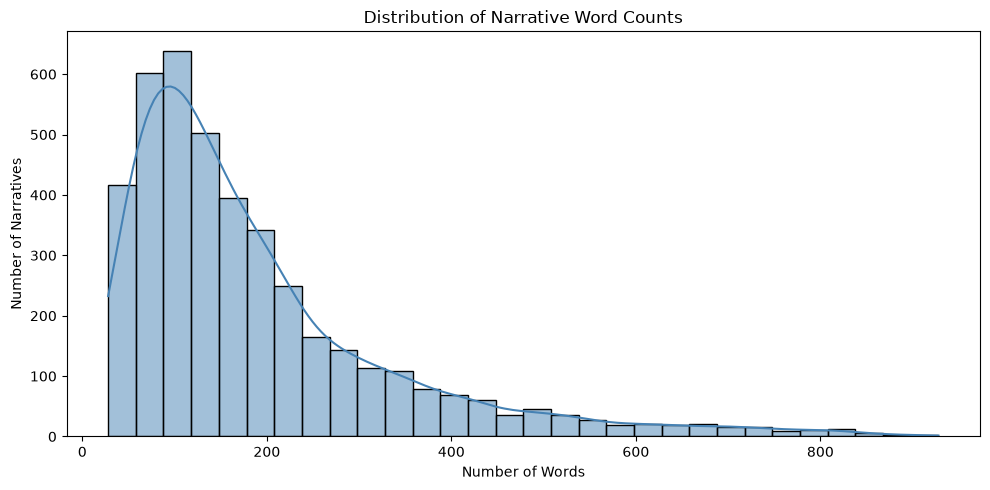

In [26]:
# Visualizing the narrative length distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=gbv,
    x="word_count",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Narrative Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Narratives")

plt.tight_layout()
plt.show()

Investigating whether GBV-related narratives tend to be longer or shorter than other crisis-related narratives

In [27]:
# Comparing narrative lengths by category
# Create a category for comparison
gbv["report_type"] = np.where(
    gbv_mask,
    "GBV-related",
    "Other crisis / No crisis"
)

# Compare descriptive statistics
gbv.groupby("report_type")["word_count"].describe()

,count,mean,std,min,25%,50%,75%,max
report_type,,,,,,,,
GBV-related,1257.0,265.007955,175.100872,30.0,136.00,214.0,344.0,928.0
Other crisis / No crisis,2922.0,157.621834,124.567672,28.0,76.25,121.0,195.0,920.0


GBV-related narratives have a higher average word count (265 words) compared with other crisis-related or no-crisis narratives (158 words).

The median word count is also higher for GBV-related narratives (214 words) than for other reports (121 words).

Additionally, GBV-related narratives show greater variation in length, with a standard deviation of approximately 175 words compared with 125 words for other reports.

These findings indicate that GBV-related narratives tend to be longer and more variable in length within this dataset.

This is important for NLP modelling because longer narratives may exceed transformer token limits and require additional handling during preprocessing.

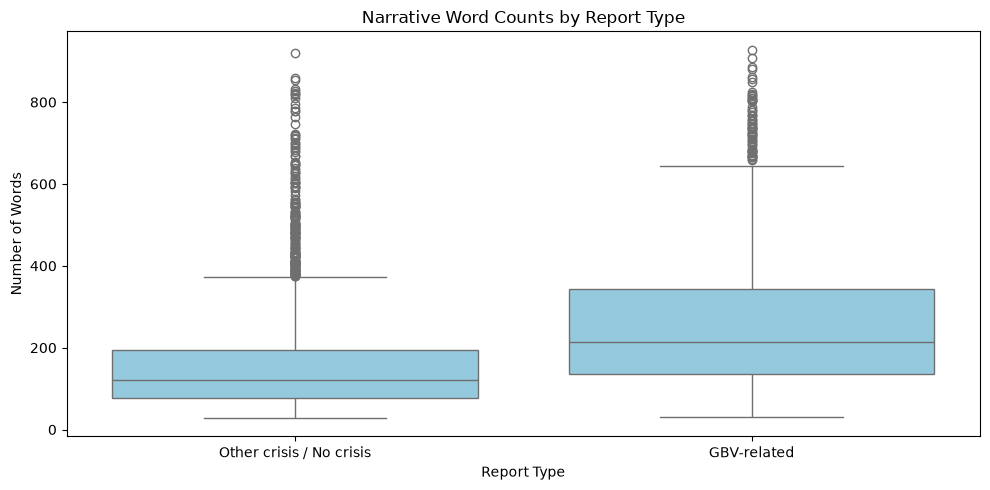

In [28]:
# Visualizing using boxplots
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=gbv,
    x="report_type",
    y="word_count",
    color="skyblue"
)

plt.title("Narrative Word Counts by Report Type")
plt.xlabel("Report Type")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.show()

The boxplot shows that GBV-related narratives generally contain more words than other crisis-related or no-crisis narratives.

The median word count for GBV-related narratives is 214 words, compared with 121 words for other reports.

GBV-related narratives also have a wider interquartile range, indicating greater variability in narrative length.

Both groups contain numerous upper outliers, with some narratives approaching 900 words.

These findings suggest that GBV-related reports tend to be longer and more variable in length. However, narrative length alone is not sufficient to identify GBV, as the distributions overlap considerably.

The unusually long narratives will be retained because they may contain important contextual information relevant to classification and crisis detection.

In [29]:
# Exploring narrative counts by each gbv category
# Select GBV-related records
gbv_lengths = gbv_analysis[
    gbv_analysis["num_gbv_categories"] > 0].copy()

# Calculate word counts
gbv_lengths["word_count"] = (
    gbv_lengths["question_text"].str.split().str.len()
)

# Convert binary category columns into long format
gbv_lengths = gbv_lengths.melt(
    id_vars=["word_count"],
    value_vars=gbv_categories,
    var_name="GBV_Category",
    value_name="Present"
)

# Keep only categories present in each narrative
gbv_lengths = gbv_lengths[
    gbv_lengths["Present"] == 1
]

# Compare narrative lengths
gbv_lengths.groupby("GBV_Category")["word_count"].describe()

,count,mean,std,min,25%,50%,75%,max
GBV_Category,,,,,,,,
childabuse_endangerment,182.0,293.049451,189.583122,51.0,154.25,252.0,364.75,887.0
domesticviolence,500.0,266.036000,161.434497,36.0,148.00,222.5,340.00,861.0
rape,407.0,240.653563,175.032004,40.0,115.00,188.0,318.50,887.0
sexualharassment,373.0,294.152815,179.741229,30.0,163.00,263.0,370.00,928.0


Sexual harassment had the highest average word count (294 words), followed by child abuse/endangerment (293 words), domestic violence (266 words) and rape (241 words).

Child abuse/endangerment showed the greatest variation in narrative length, while all four categories contained some unusually long reports.

These findings indicate that narrative lengths vary across the annotated GBV categories. However, word count alone cannot determine the type or severity of violence.

The results also highlight the importance of selecting an appropriate tokenisation strategy to preserve relevant information during transformer modelling.

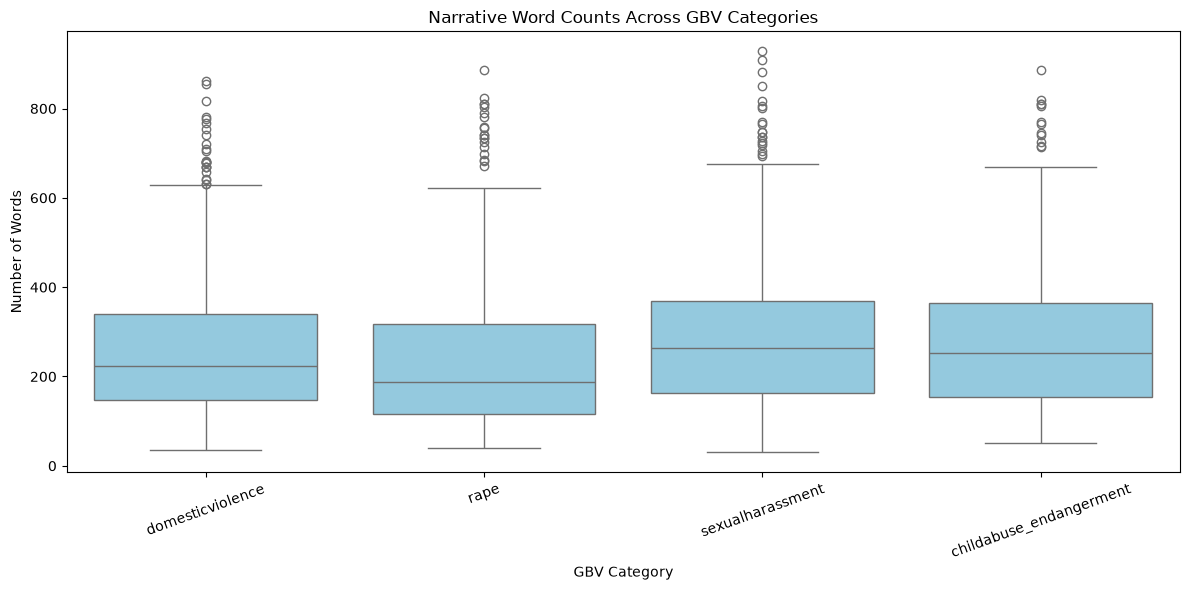

In [30]:
# Visualizing using boxplots
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=gbv_lengths,
    x="GBV_Category",
    y="word_count",
    color="skyblue"
)

plt.title("Narrative Word Counts Across GBV Categories")
plt.xlabel("GBV Category")
plt.ylabel("Number of Words")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

The boxplot shows differences in narrative lengths across the four GBV-related categories.

Sexual harassment has the highest median word count (263 words), followed by child abuse/endangerment (252 words), domestic violence (223 words) and rape (188 words).

Sexual harassment has the widest interquartile range, while child abuse/endangerment has the highest standard deviation, indicating greater overall variability.

All four categories contain unusually long narratives, with several exceeding 800 words.

Although narrative lengths differ across categories, the distributions overlap considerably. Therefore, word count alone cannot reliably identify the type of GBV.

In [31]:
# Checking text length characters
gbv["char_count"] = gbv["question_text"].str.len()

# Descriptive statistics
gbv["char_count"].describe()

count    4179.000000
mean      987.885379
std       775.178094
min       160.000000
25%       460.000000
50%       745.000000
75%      1232.500000
max      4751.000000
Name: char_count, dtype: float64

*Text Preprocessing*

In [72]:
# Light text cleaning: Removing white spaces
import re
import pandas as pd

# Text cleaning function
def clean_text(text):

    # Handle missing values
    if pd.isna(text):
        return ""

    # Convert input to string
    text = str(text)

    # Remove the repeated CRADLE instruction
    text = re.sub(
        r"For any crisis present, mark whether it is Ongoing or Past\.",
        "",
        text,
        flags=re.IGNORECASE
    )

    # Mask email addresses
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
        "[EMAIL]",
        text
    )

    # Mask URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        "[URL]",
        text,
        flags=re.IGNORECASE
    )

    # Remove Title: at the beginning
    text = re.sub(
        r"^\s*Title\s*:\s*",
        "",
        text,
        flags=re.IGNORECASE
    )

    # Replace Text: separator with a full stop
    text = re.sub(
        r"\s+Text\s*:\s*",
        ". ",
        text,
        count=1,
        flags=re.IGNORECASE
    )

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Remove duplicated punctuation at title/body boundary
    text = re.sub(r"([.!?])\s*\.\s+", r"\1 ", text)

    return text

In [67]:
sample = "Title: I NEED HELP 😭 Text: My partner keeps threatening me!!!"

print(clean_text(sample))

I NEED HELP 😭. My partner keeps threatening me!!!


Note that we are not removing stop words or punctuation as we are working with sensitive narratives. Transformer models also benefit from retaining natural sentence structure.

In [69]:
# COnfirming that cleaning worked
print("Original text:")
print(gbv["question_text"].iloc[0])

print("\nCleaned text:")
print(gbv["clean_text"].iloc[0])

Original text:
Title: Workplace Sexual Harassment while WFH

Text: Hi,

Hope it's ok to post here, but please let me know if not! I was wondering whether anyone has experienced sexual harassment from a colleague while working from home i.e. inappropriate texts, messages/comments during Zoom calls and Slack etc. Also looking to speak to anyone who reported a colleague for sexual harassment before or during lockdown and had their case delayed or poorly handled.

I'm currently working on a sensitive article to highlight issues women are facing while working from home and would like to amplify women's voices while doing so. If you feel comfortable doing so, please message me or email: [scarletemily.hannington@gmail.com](mailto:scarletemily.hannington@gmail.com). You can remain completely anonymous.

For any crisis present, mark whether it is Ongoing or Past. 
**Leave a row blank if that crisis type is not present.**

Cleaned text:
Title: Workplace Sexual Harassment while WFH Text: Hi, Hope

In [70]:
# Checking how often the annotation instruction appears
instruction_mask = gbv["clean_text"].str.contains(
    "For any crisis present",
    case=False,
    regex=False,
    na=False
)

print("Narratives containing annotation instructions:",
      instruction_mask.sum())

print("Narratives without annotation instructions:",
      (~instruction_mask).sum())

Narratives containing annotation instructions: 0
Narratives without annotation instructions: 4179


In [71]:
# Removing the annotation instructions
gbv["clean_text"] = gbv["clean_text"].str.replace(
    r"For any crisis present, mark whether it is Ongoing or Past\..*$",
    "",
    regex=True
).str.strip()

# Confirm removal
print("Remaining annotation instructions:",
      gbv["clean_text"].str.contains(
          "For any crisis present",
          case=False,
          regex=False
      ).sum())

print("\nCleaned narrative:")
print(gbv["clean_text"].iloc[0])

Remaining annotation instructions: 0

Cleaned narrative:
Title: Workplace Sexual Harassment while WFH Text: Hi, Hope it's ok to post here, but please let me know if not! I was wondering whether anyone has experienced sexual harassment from a colleague while working from home i.e. inappropriate texts, messages/comments during Zoom calls and Slack etc. Also looking to speak to anyone who reported a colleague for sexual harassment before or during lockdown and had their case delayed or poorly handled. I'm currently working on a sensitive article to highlight issues women are facing while working from home and would like to amplify women's voices while doing so. If you feel comfortable doing so, please message me or email: [[EMAIL]](mailto:[EMAIL]). You can remain completely anonymous.


In [65]:
# Masking emails and urls
gbv["clean_text"] = gbv["clean_text"].str.replace(
    r"[\w\.-]+@[\w\.-]+\.\w+",
    "[EMAIL]",
    regex=True
)

# Mask Markdown links while preserving their visible text
gbv["clean_text"] = gbv["clean_text"].str.replace(
    r"\[([^\]]+)\]\(https?://[^)]+\)",
    r"\1",
    regex=True
)

# Mask remaining URLs
gbv["clean_text"] = gbv["clean_text"].str.replace(
    r"https?://\S+|www\.\S+",
    "[URL]",
    regex=True
)

# Preview the cleaned narrative
print(gbv["clean_text"].iloc[0])

Title: Workplace Sexual Harassment while WFH Text: Hi, Hope it's ok to post here, but please let me know if not! I was wondering whether anyone has experienced sexual harassment from a colleague while working from home i.e. inappropriate texts, messages/comments during Zoom calls and Slack etc. Also looking to speak to anyone who reported a colleague for sexual harassment before or during lockdown and had their case delayed or poorly handled. I'm currently working on a sensitive article to highlight issues women are facing while working from home and would like to amplify women's voices while doing so. If you feel comfortable doing so, please message me or email: [[EMAIL]](mailto:[EMAIL]). You can remain completely anonymous.


In [66]:
# Identify GBV-related narratives
gbv_mask = gbv["final_labels"].str.contains(
    "domesticviolence|rape|sexualharassment|childabuse_endangerment",
    case=False,
    regex=True,
    na=False
)

# Randomly select 10 GBV-related narratives
sample_gbv = gbv.loc[
    gbv_mask,
    ["clean_text", "final_labels"]
].sample(n=10, random_state=42)

# Display complete narratives
pd.set_option("display.max_colwidth", None)

display(sample_gbv)

,clean_text,final_labels
1472,"Title: I wish I never left him. Text: I’m tired. I’m so fucking tired. I spent 8 years with him. He abused me every chance he could get. Of course, during this 8 years I lied a lot to my family and friends. I said he wasn’t living with me when he was. I told them I wasn’t talking to him when I was. I accept my faults and my mistakes. I have apologised profusely. I was trauma bonded to him and lying to cover for him/us became my second nature. I finally, completely broke it off. It’s been over a year and every one still treats me like a liar. My family, since I left him, have been coming down hard on me. They’re quick and cruel. They gaslight me, say I’m a “mental case” and that I’m “the girl who cried wolf”. The lies spiralling around me aren’t even coming from me anymore. They’re coming from my siblings. From other family members who live close by, saying that my ex is back in my house (he’s not - I wouldn’t even risk it. The trauma bond is broken.) But every single day, I’m dealing with somebody shouting at me, calling me a liar or just calling me “nuts”, “mental” and “psycho.” I wish I never left him. At least he had the balls to back up his words with physical actions. Now, I just feel like I’m everyone’s punch bag. Just emotionally and verbally. I’m so tired.",domesticviolence_past
372,Title: Can any other female relate to this SA experience? Text: I was recently raped but feel really guilty that my body enjoyed it even if I didn't want it. I'm not sure if my body was trying to protect me because I had a lot of lubrication from the stimulation itself. For me personally I unfortunately ended up orgasming twice from when he want down on me and during penetration when he was hitting my gspot. I didn't want it to happen but my body betrayed me and it did honestly feel good. Has anyone else experienced unwanted orgasms like I did? How do you deal with it?,rape_ongoing
186,"Title: Am I in the wrong? Text: I don’t know how to feel about this right now. The individual Im copy/pasting our conversation with below has been warned by me and several other in our friend group to not touch or act inappropriatly around (as well has been fired from several jobs for sexual harassment) Me: man I like hanging out with you but I have to ask that you cool it with the touching and the sexual stuff. I respect the way you live but touching is already a hard barrier for me and the innuendos and gestures are not ok. I don't want this to be a divide or risk causing tension in the friend group so I'm asking you nicely as a man to respect my space so that way we can still be friends and hangout Him: You are such a beautiful soul no matter how tough you try to be, I love you and how about we meet in the middle what if I sexually assault brody instead from now on and you know that I care enough about you to settle for him instead. Me: Not cool I've set the the boundary and if you refuse to respect it I won't treat this as comradely but as a direct sign of disrespect Him: Ok well that is a respectable but what if brody actually wants it? Me: That's between you and him. I don't feel comfortable with the invasion of my personal space if he decides for himself that's for him and you nothing to do with what's going on here. Him: Ok well just know I love you baby and I can't wait to have a completely fun platonic time at renfest tomorrow. But to be fair I literally saw brody grapple you and bring you to the ground so if that hasn't been a 10 times greater abuse of personal space that you didn't address tonight then I am going to not believe a complete word you are saying because it's incredibly hypothetical unless it's OK for me to get physical with you if I just use far more excessive force. Me: No don't try that bullshit. context and trust went into me being ok with that. I've asked you multiple time to stay out of my personal space and you've ignored me. I know if I feel uncomfortable and ask Brody to stop he will especially 

In [39]:
# Examining narratives without GBV labels
non_gbv_sample = gbv.loc[
    ~gbv_mask,
    ["clean_text", "final_labels"]
].sample(n=10, random_state=42)

pd.set_option("display.max_colwidth", None)

display(non_gbv_sample)

,clean_text,final_labels
589,"Title: I hate school Text: It’s 1 AM rn, I have an exam tomorrow, I didn’t study at all since I had too much homework for the whole week, I’m going to fail so bad. This exam is important, it’s one of my most important subject so I’m in deep ****. I’m so stressed i really need to cut but I know it’ll just add problems",selfharm_ongoing
2635,"Title: I really need a friend right now Text: Someone please talk to me. I made thdi throwaway even though I’ve openly posted about feelings and struggles with suicidal thoughts on my main account because I didn’t give a fuck. I was more open on this one because of lies I’ve told other close Reddit friends that I’m ashamed of. Reddit won’t let me DM people on this account that I’ve tried to reach out to so as to not be 100% lonely, but I’m just stuck drinking more and commenting on posts like a helpless moron. If you wanna know more about me, DM me, read my first post from around an hour ago, or both. I just really need someone to talk to. I can’t go on like this without freaking out more than I already am.",suicideideation_passive_ongoing
1890,"Title: Any guys here? Text: ive been reading articles about self harming, and most of them say that alot more girls sh than guys. any guys here?",no_crisis
701,Title: okay so finally have a method i think will work Text: Okay so that's jumping off 40-50 meters (aproxx147 feet) building okay so idk if this will kill me but if i try then I'm gonna be fucked if it doesn't but rn i don't even have the courage to do it how can I get the courage? And will I die if i actually do it?,suicideideation_active_ongoing
2854,"Title: After a failed attempt I was taken to ER Text: Im still at the hospital, how long will they keep me for? I’m already been there for over 12 hours. I had a lot to drink and tried to drown myself in the tub.",suicideideation_active_ongoing
286,Title: June 17th 2023/2024. Text: I want it to be on my birthday. Depends how long I can last.,suicideideation_active_ongoing
2470,"Title: Im gonna do it Text: Im finally gonna do it. Im gonna man up and ask out a girl i like. Wish me luck. Ill add an edit to this post afterwards to let yall know how it goes Update: she said yes, but said well do it next week because of school stuff Long story short: ***i got a date*** Update 2: so we hang out and i didnt tell her i liked her till just recently. She rejected me. Whoopty fuckin doo",no_crisis
2811,Title: I’m tired. Text: I’m tired. I’m tired of being me. I’m just tired.,suicideideation_passive_ongoing
3743,"Title: would it affect me much if I gave up medicine after two days of taking it? Text: Hello, before I'll explain everything. I have epilepsy medicine reluctant(yes, I remembered to add it's medicine reluctant, I am smart enough), and the psychiatrist is aware of it. And that's the matter because I've been having convulsions, my hands trembles so much it's hard to write and I cannot do anything because I feel dizziness. I decided to read the text included with medicine, and it's crystal clear written few times that I should not take these medicines and should contact doctor, but it's 9pm, the clinic is closed and will be until Monday. I don't want to risk having seizure but the side effects after stopping getting them don't look good either. I just started so maybe stopping taking them now wouldn't be that bad, but still I need to ask you. In the past I had similar experience, I had been taking the medicines prescribed by psychiatrist (different one) but I stopped because I started getting a lot of seizures, and it's definitely something I don't want to repeat. Before I'll get scolded why I write it now. I thought that these are part of some sort heavier anxiety attack, I got into hospital two weeks ago because I couldn't breath(sorry, I forgot the word) due to heavy stress, and I had similar experience as well, so I automatically connected it to this not to epilepsy. I just happened to have time and check the text

**Tokeniazation**

DistilBERT converts text into smaller units called tokens before processing it. DistilBERT typically accepts a maximum of 512 tokens per input, including special tokens.

In [41]:
# Loading the tokenizer
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

print("Tokenizer loaded successfully!")

c:\Users\Admin\Desktop\Final_Capstone\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Tokenizer loaded successfully!


In [60]:
# Calculating the token count for each narrative
gbv["token_count"] = gbv["clean_text"].apply(
    lambda text: len(
        tokenizer.encode(
            text,
            add_special_tokens=True,
            truncation=False
        )
    )
)

# Display descriptive statistics
gbv["token_count"].describe()

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (553 > 512). Running this sequence through the model will result in indexing errors


count    4179.000000
mean      208.158650
std       181.152632
min        12.000000
25%        85.000000
50%       151.000000
75%       265.000000
max      1113.000000
Name: token_count, dtype: float64

Tokenisation was performed using the pretrained DistilBERT tokenizer.

The 4,179 narratives contained an average of approximately 208 tokens and a median of 151 tokens.

Token counts ranged from 12 to 1,113, with a standard deviation of approximately 181 tokens.

The distribution was positively skewed, indicating that most narratives were relatively short, while some were considerably longer.

Although at least 75% of narratives fall within DistilBERT's maximum input length of 512 tokens, some exceed this limit.

Further analysis is required to determine the proportion of long narratives and select an appropriate strategy for handling them without unnecessarily losing important information.

In [74]:
# Counting narratives that exceed 512 tokens
long_narratives = (gbv["token_count"] > 512).sum()

print("Narratives exceeding 512 tokens:", long_narratives)

print(
    "Percentage:",
    round(long_narratives / len(gbv) * 100, 2), "%"
)

Narratives exceeding 512 tokens: 299
Percentage: 7.15 %


Token-length analysis showed that 3,880 narratives (92.85%) fall within DistilBERT's maximum input length of 512 tokens.

The remaining 299 narratives (7.15%) exceed this limit.

Although most narratives can be processed without truncation, longer narratives may contain important information toward the end of the text.

Therefore, chunking will be considered as an alternative to truncation, particularly because the project involves sensitive GBV-related content. The final approach will consider information preservation, computational cost and model performance.

In [75]:
# Select narratives exceeding 512 tokens
long_texts = gbv[gbv["token_count"] > 512]

# Summarise their token lengths
long_texts["token_count"].describe()

count     299.000000
mean      704.224080
std       143.121411
min       513.000000
25%       586.500000
50%       661.000000
75%       796.500000
max      1113.000000
Name: token_count, dtype: float64

Among these longer narratives, the average token count was approximately 704, with a median of 661 and a maximum of 1,113 tokens.

These findings suggest that truncating all narratives at 512 tokens could result in the loss of potentially important information.

An overlapping chunking approach will therefore be explored to preserve the content of longer narratives. Shorter narratives will remain as single inputs.

Chunking will be performed the training, validation and test datasets to prevent information leakage. Model predictions will be evaluated at the original narrative level.

In [76]:
# Checking the tokenizers special tokens
sample_text = "I need counselling and support."

tokens = tokenizer.tokenize(sample_text)

encoded_tokens = tokenizer.encode(
    sample_text,
    add_special_tokens=True
)

print("Tokens:", tokens)

print("\nTokens with special tokens:")
print(tokenizer.convert_ids_to_tokens(encoded_tokens))

print("\nNumber of special tokens:",
      tokenizer.num_special_tokens_to_add(pair=False))

Tokens: ['i', 'need', 'counsel', '##ling', 'and', 'support', '.']

Tokens with special tokens:
['[CLS]', 'i', 'need', 'counsel', '##ling', 'and', 'support', '.', '[SEP]']

Number of special tokens: 2


In [73]:
# Creating the chunking function
def chunk_text(text, tokenizer, max_length=512, overlap=64):

    # Convert text into token IDs without special tokens
    token_ids = tokenizer.encode(
        text,
        add_special_tokens=False,
        truncation=False
    )

    # Reserve space for [CLS] and [SEP]
    max_content_length = max_length - tokenizer.num_special_tokens_to_add(pair=False)

    # Validate the overlap
    if not 0 <= overlap < max_content_length:
        raise ValueError("Overlap must be smaller than the chunk size.")

    # Calculate how far to move for each new chunk
    step = max_content_length - overlap

    chunks = []

    for start in range(0, len(token_ids), step):

        # Extract the tokens for the current chunk
        chunk_ids = token_ids[start:start + max_content_length]

        # Add [CLS] and [SEP] special tokens
        chunk_ids = (
            [tokenizer.cls_token_id]
            + chunk_ids
            + [tokenizer.sep_token_id]
        )

        # Store the chunk
        chunks.append(chunk_ids)

        # Stop when all tokens have been included
        if start + max_content_length >= len(token_ids):
            break

    return chunks

For a narrative containing 700 content tokens:
- Chunk 1: Tokens 1–510
- Chunk 2: Tokens 447–700

The chunks overlap by 64 tokens, reducing the risk of losing context at chunk boundaries.
For narratives shorter than 510 content tokens, the function produces only one chunk.

In [77]:
# Testing the function
# Select the longest narrative
longest_text = gbv.loc[
    gbv["token_count"].idxmax(),
    "clean_text"
]

# Split into chunks
test_chunks = chunk_text(longest_text, tokenizer)

print("Number of chunks:", len(test_chunks))

# Check the length of each chunk
for i, chunk in enumerate(test_chunks):
    print(f"Chunk {i+1}: {len(chunk)} tokens")

Number of chunks: 3
Chunk 1: 512 tokens
Chunk 2: 512 tokens
Chunk 3: 221 tokens


In [78]:
def chunk_text(text, tokenizer, max_length=512, overlap=64):

    # Tokenize without truncation or special tokens
    token_ids = tokenizer.encode(
        text,
        add_special_tokens=False,
        truncation=False
    )

    # Reserve space for [CLS] and [SEP]
    max_content_length = max_length - 2

    # Number of tokens to advance
    step = max_content_length - overlap

    chunks = []

    for start in range(0, len(token_ids), step):

        # Extract a section of the original token IDs
        chunk_ids = token_ids[start:start + max_content_length]

        # Add DistilBERT's special tokens
        chunk_ids = tokenizer.build_inputs_with_special_tokens(
            chunk_ids
        )

        chunks.append(chunk_ids)

        # Stop after reaching the end
        if start + max_content_length >= len(token_ids):
            break

    return chunks

In [79]:
# Checking if the tokenizer is preserving all tokens
# Original token count
original_tokens = tokenizer.encode(
    longest_text,
    add_special_tokens=True,
    truncation=False
)

print("Original token count:", len(original_tokens))

# Check tokenizer configuration
print("Tokenizer maximum length:", tokenizer.model_max_length)

# Check total tokens returned by chunking
print("Chunk lengths:", [len(chunk) for chunk in test_chunks])

Original token count: 1113
Tokenizer maximum length: 512
Chunk lengths: [512, 512, 221]


In [80]:
# Original tokens without special tokens
original_ids = tokenizer.encode(
    longest_text,
    add_special_tokens=False,
    truncation=False
)

# Reconstruct the original tokens from the chunks
reconstructed_ids = []

for i, chunk in enumerate(test_chunks):

    # Remove [CLS] and [SEP]
    content_ids = chunk[1:-1]

    if i == 0:
        reconstructed_ids.extend(content_ids)
    else:
        # Remove the repeated overlap
        reconstructed_ids.extend(content_ids[64:])

print("Original content tokens:", len(original_ids))
print("Reconstructed tokens:", len(reconstructed_ids))
print("All tokens preserved:", original_ids == reconstructed_ids)

Original content tokens: 1111
Reconstructed tokens: 1111
All tokens preserved: True


The chunking function successfully prepares long narratives for DistilBERT without discarding content. During model development, chunks belonging to the same narrative will be kept together to prevent data leakage, and their predictions will be combined at the narrative level.

Counting the chunks helps determine:
    - How many model inputs will be generated.
    - How many narratives require multiple chunks.
    - The additional computational requirements for training.

Each chunk will retain its association with the original narrative and its target labels.

Although DistilBERT processes individual chunks, final classification results will be evaluated at the narrative level by combining predictions from chunks belonging to the same narrative.

In [81]:
# Inspecting existing labels
print(gbv["final_labels"].head(10).to_string(index=False))

                                        no_crisis
                         domesticviolence_ongoing
                         sexualharassment_ongoing
                                        no_crisis
                                        no_crisis
                            domesticviolence_past
                                        no_crisis
                                        no_crisis
suicideideation_passive_ongoing, selfharm_ongoing
                   suicideideation_active_ongoing


In [136]:
print(gbv.columns.tolist())

['question_id', 'question_text', 'final_labels', 'word_count', 'report_type', 'char_count', 'clean_text', 'token_count', 'domesticviolence', 'rape', 'sexualharassment', 'childabuse_endangerment', 'gbv_label_count', 'chunks', 'num_chunks']


In [137]:
print("Narratives with at least one GBV label:",
      (gbv["gbv_label_count"] > 0).sum())

print("Narratives with no selected GBV label:",
      (gbv["gbv_label_count"] == 0).sum())

Narratives with at least one GBV label: 1257
Narratives with no selected GBV label: 2922


In [138]:
# Select narratives without our four GBV labels
unclassified = gbv[gbv["gbv_label_count"] == 0]

# Inspect the original label combinations
print(unclassified["final_labels"].value_counts().head(20))

final_labels
no_crisis                                                                         1160
selfharm_ongoing                                                                   558
suicideideation_passive_ongoing                                                    438
suicideideation_active_ongoing                                                     365
selfharm_past                                                                      187
suicideideation_passive_ongoing, selfharm_ongoing                                   76
suicideideation_active_ongoing, selfharm_ongoing                                    49
suicideideation_active_past, suicideideation_passive_ongoing                        25
suicideideation_active_past                                                         15
suicideideation_passive_ongoing, suicideideation_active_ongoing                     11
suicideideation_passive_past                                                        11
suicideideation_passive_ongoin

In [139]:
# Create the fifth classification label
gbv["no_crisis"] = (
    gbv["final_labels"].astype(str).str.strip().eq("no_crisis")
).astype(int)

# Check the new label distribution
print(gbv["no_crisis"].value_counts())

no_crisis
0    3019
1    1160
Name: count, dtype: int64


In [141]:
gbv[gbv["no_crisis"] == 1][
    ["question_text", "final_labels", "no_crisis"]
].head(10)

,question_text,final_labels,no_crisis
0,"Title: Workplace Sexual Harassment while WFH\n\nText: Hi,\n\nHope it's ok to post here, but please let me know if not! I was wondering whether anyone has experienced sexual harassment from a colleague while working from home i.e. inappropriate texts, messages/comments during Zoom calls and Slack etc. Also looking to speak to anyone who reported a colleague for sexual harassment before or during lockdown and had their case delayed or poorly handled.\n\nI'm currently working on a sensitive article to highlight issues women are facing while working from home and would like to amplify women's voices while doing so. If you feel comfortable doing so, please message me or email: [scarletemily.hannington@gmail.com](mailto:scarletemily.hannington@gmail.com). You can remain completely anonymous.\n\nFor any crisis present, mark whether it is Ongoing or Past. \n**Leave a row blank if that crisis type is not present.**",no_crisis,1
3,"Title: [URGENT] I think a friend committed suicide. Please help.\n\nText: *******IMPORTANT EDIT******* I NEED TO COME CLEAN WITH ALL OF YOU GUYS, THIS PERSON IS NOT JUST A FRIEND BUT A PAID THERAPIST. THE COMPANY THEY ARE EMPLOYED WITH DOES NOT TOLERATE NO SHOWS WELL SO THIS IS WHY IT IS CONCERNING. EVERYTHING ELSE IS ACCURATE IN MU POST. ******They have been talking about it last week but let me know they sought out crisis help and for a therapist. Today we were supposed to virtually meet up and they did not show up. Not answering texts either. I’m praying to God that this did not happen. I don’t know what to do. I don’t have any other way to contact them or their family. I feel like a piece of shit for not checking up on them or doing anything. I’m praying that this didn’t happen. Oh God\n\nEdit 1: still no reply from them. It’s been ~10 hours since I’ve first reached out to them. I was able to find what I assume their address. Attempted to call their local PD for a welfare check but they are closed on the weekends. No social media of theirs was found. I found their old cell phone number which is either off or disconnected (most likely). I found what I assume their wife’s or daughter’s cell phone which goes directly to voicemail as well.\n\nPlease don’t spend your money to give me awards.\n\nEdit 2: Wanted to give you guys a quick update and thank all of you for the well wishes, advice, and just plain support you have provided me in these times. \n\nThis morning I got an email from the company he works for. They told me that he is away due to a medical emergency. This means he is ALIVE. I am so happy all of my and your prayers have been answered. I do not know more details except those from the email but I will try to update you guys with the whole story when I can. I am also not aware if the medical emergency is due to a suicide attempt.\n\nFor any crisis present, mark whether it is Ongoing or Past. \n**Leave a row blank if that crisis type is not present.**",no_crisis,1
4,"Title: Feel socially incompetent and anxious many days a week\n\nText: I'm not sure if this is the place to ask this, if not, please tell me which sub would be better. \n\nRight now I'm feeling amazing, I feel fully aware of myself and my surroundings, confident and capable. Which only makes me wonder why most of the other time I feel so shitty (for no apparent reason). \n\nThere're many days when my mind just feels clouded, I feel tired and sleepy, and I struggle with social interactions often being very akward. Activities that I can perform perfectly fine, such as driving or cooking don't come natural to me and make me feel very nervous. I often find myself being distracted very easyly\n\nOn good days I feel fully confident of myself. I feel happier, more capable of performing my daily activities, and I think I could even pass as kind of charismatic when interacting with others. \n\nI've attributed it maybe to a bad sleep schedule, but even on days when I get plenty of sleep I can still feel sh

In [142]:
gbv_labels = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment"
]

conflicting_labels = gbv[
    (gbv["no_crisis"] == 1) &
    (gbv[gbv_labels].sum(axis=1) > 0)
]

print("Conflicting annotations:", len(conflicting_labels))

Conflicting annotations: 0


In [143]:
# Select narratives originally labelled No Crisis
no_crisis_review = gbv[gbv["no_crisis"] == 1].copy()

# Add columns for manual annotation
no_crisis_review["reviewed_label"] = ""
no_crisis_review["review_notes"] = ""

# Display the first 10 narratives for review
no_crisis_review[
    ["question_id", "clean_text", "final_labels",
     "reviewed_label", "review_notes"]
].head(10)

,question_id,clean_text,final_labels,reviewed_label,review_notes
0,Question 1,"Title: Workplace Sexual Harassment while WFH Text: Hi, Hope it's ok to post here, but please let me know if not! I was wondering whether anyone has experienced sexual harassment from a colleague while working from home i.e. inappropriate texts, messages/comments during Zoom calls and Slack etc. Also looking to speak to anyone who reported a colleague for sexual harassment before or during lockdown and had their case delayed or poorly handled. I'm currently working on a sensitive article to highlight issues women are facing while working from home and would like to amplify women's voices while doing so. If you feel comfortable doing so, please message me or email: [[EMAIL]](mailto:[EMAIL]). You can remain completely anonymous.",no_crisis,,
3,Question 4,"Title: [URGENT] I think a friend committed suicide. Please help. Text: *******IMPORTANT EDIT******* I NEED TO COME CLEAN WITH ALL OF YOU GUYS, THIS PERSON IS NOT JUST A FRIEND BUT A PAID THERAPIST. THE COMPANY THEY ARE EMPLOYED WITH DOES NOT TOLERATE NO SHOWS WELL SO THIS IS WHY IT IS CONCERNING. EVERYTHING ELSE IS ACCURATE IN MU POST. ******They have been talking about it last week but let me know they sought out crisis help and for a therapist. Today we were supposed to virtually meet up and they did not show up. Not answering texts either. I’m praying to God that this did not happen. I don’t know what to do. I don’t have any other way to contact them or their family. I feel like a piece of shit for not checking up on them or doing anything. I’m praying that this didn’t happen. Oh God Edit 1: still no reply from them. It’s been ~10 hours since I’ve first reached out to them. I was able to find what I assume their address. Attempted to call their local PD for a welfare check but they are closed on the weekends. No social media of theirs was found. I found their old cell phone number which is either off or disconnected (most likely). I found what I assume their wife’s or daughter’s cell phone which goes directly to voicemail as well. Please don’t spend your money to give me awards. Edit 2: Wanted to give you guys a quick update and thank all of you for the well wishes, advice, and just plain support you have provided me in these times. This morning I got an email from the company he works for. They told me that he is away due to a medical emergency. This means he is ALIVE. I am so happy all of my and your prayers have been answered. I do not know more details except those from the email but I will try to update you guys with the whole story when I can. I am also not aware if the medical emergency is due to a suicide attempt.",no_crisis,,
4,Question 5,"Title: Feel socially incompetent and anxious many days a week Text: I'm not sure if this is the place to ask this, if not, please tell me which sub would be better. Right now I'm feeling amazing, I feel fully aware of myself and my surroundings, confident and capable. Which only makes me wonder why most of the other time I feel so shitty (for no apparent reason). There're many days when my mind just feels clouded, I feel tired and sleepy, and I struggle with social interactions often being very akward. Activities that I can perform perfectly fine, such as driving or cooking don't come natural to me and make me feel very nervous. I often find myself being distracted very easyly On good days I feel fully confident of myself. I feel happier, more capable of performing my daily activities, and I think I could even pass as kind of charismatic when interacting with others. I've attributed it maybe to a bad sleep schedule, but even on days when I get plenty of sleep I can still feel shitty. So, I was just wondering what could possibly cause such a hard difference on my... mood?, personality?, from day to day. I really have no idea if this is something that I should consult with a psychologist or a psychiatrist, or if this is a change that most people can experi

The ´no_crisis´ column has variety of narrations that include gbv-related contexts and others not related to the scope of the project. Since we want to include these misclassified gbv related issues, we'll use keyword-based filtering with rule-based pattern matching(Regex)

In [146]:
# Creating a GBV keyword dictionary
gbv_keywords = {
    "domesticviolence": [
        "domestic violence",
        "domestic abuse",
        "physical abuse",
        "abusive partner",
        "hit me",
        "beat me",
        "threatened me",
        "controlling partner",
        "intimate partner violence"
    ],

    "rape": [
        "rape",
        "raped",
        "sexual assault",
        "sexually assaulted",
        "forced sex",
        "non consensual",
        "without consent",
        "sexual coercion",
        "molested"
    ],

    "sexualharassment": [
        "sexual harassment",
        "sexually harassed",
        "unwanted touching",
        "inappropriate touching",
        "sexual comments",
        "unwanted advances",
        "sexual messages",
        "catcalling"
    ],

    "childabuse_endangerment": [
        "child abuse",
        "abused as a child",
        "abusive parent",
        "stepfather",
        "stepmother",
        "underage",
        "minor",
        "child molestation",
        "neglected child",
        "child exploitation"
    ]
}

for category, keywords in gbv_keywords.items():
    print(f"{category}: {len(keywords)} keywords")

domesticviolence: 9 keywords
rape: 9 keywords
sexualharassment: 8 keywords
childabuse_endangerment: 10 keywords


Note that these are screening terms and not validated GBV vocab as some are not inherently evidence of abuse. They are only added to help identify narratives worth reviewing.

Also to note, this screening process does not automatically relabel narratives. Original annotations have been preserved.

### Applying Regex for GBV Keyword Matching

Regular expressions (Regex) are used to search narratives originally labelled `no_crisis` for words and phrases associated with the four selected GBV categories.

The keyword dictionary will be converted into category-specific Regex patterns. Word boundaries were applied to reduce partial-word matches, while case-insensitive matching allowed detection regardless of capitalisation.

In [147]:
import re

# Work with the original No Crisis narratives
no_crisis_df = gbv[gbv["no_crisis"] == 1].copy()

# Create a Regex pattern for each GBV category
gbv_patterns = {}

for category, keywords in gbv_keywords.items():
    pattern = r"\b(?:" + "|".join(
        re.escape(keyword) for keyword in keywords
    ) + r")\b"

    gbv_patterns[category] = pattern

    # Check whether each narrative contains matching keywords
    no_crisis_df[f"{category}_match"] = (
        no_crisis_df["clean_text"]
        .fillna("")
        .str.contains(pattern, case=False, regex=True)
    )

# Collect the four matching columns
match_columns = [
    f"{category}_match"
    for category in gbv_keywords
]

# Flag narratives matching at least one GBV category
no_crisis_df["potential_gbv"] = (
    no_crisis_df[match_columns].any(axis=1)
)

# Summarise results
print("Total No Crisis narratives:", len(no_crisis_df))

print("\nPotential GBV narratives:")
print(no_crisis_df["potential_gbv"].value_counts())

print("\nMatches by GBV category:")
print(no_crisis_df[match_columns].sum())

Total No Crisis narratives: 1160

Potential GBV narratives:
potential_gbv
False    996
True     164
Name: count, dtype: int64

Matches by GBV category:
domesticviolence_match           39
rape_match                       66
sexualharassment_match           53
childabuse_endangerment_match    17
dtype: int64


*Identifying the exact keywords that triggered the matches*

In [148]:
# Function to identify matched keywords
def find_matched_keywords(text, pattern):
    if not isinstance(text, str):
        return []

    matches = re.findall(pattern, text, flags=re.IGNORECASE)
    return list(dict.fromkeys(match.lower() for match in matches))


# Extract matched keywords for each GBV category
for category, pattern in gbv_patterns.items():
    no_crisis_df[f"{category}_keywords"] = (
        no_crisis_df["clean_text"].apply(
            lambda text: find_matched_keywords(text, pattern)
        )
    )


# Inspect the first 10 flagged narratives
flagged_gbv = no_crisis_df[
    no_crisis_df["potential_gbv"]
].copy()

display(
    flagged_gbv[
        [
            "question_id",
            "clean_text",
            "domesticviolence_keywords",
            "rape_keywords",
            "sexualharassment_keywords",
            "childabuse_endangerment_keywords"
        ]
    ].head(10)
)

,question_id,clean_text,domesticviolence_keywords,rape_keywords,sexualharassment_keywords,childabuse_endangerment_keywords
0,Question 1,"Title: Workplace Sexual Harassment while WFH Text: Hi, Hope it's ok to post here, but please let me know if not! I was wondering whether anyone has experienced sexual harassment from a colleague while working from home i.e. inappropriate texts, messages/comments during Zoom calls and Slack etc. Also looking to speak to anyone who reported a colleague for sexual harassment before or during lockdown and had their case delayed or poorly handled. I'm currently working on a sensitive article to highlight issues women are facing while working from home and would like to amplify women's voices while doing so. If you feel comfortable doing so, please message me or email: [[EMAIL]](mailto:[EMAIL]). You can remain completely anonymous.",[],[],[sexual harassment],[]
15,Question 16,"Title: Sexual Harassment Questionnaire Text: Selective Insurance is the lowest bid for local governments (towns, cities, boroughs) to buy for their government employees. (So, as we all know the lowest bidder wins the contract.) S.I. has these insured people (eg. council members, cops, garbage people, etc.) take a sexual harassment questionnaire, (sounds great, right?) however it is impossible to fail it, because when a question is answered incorrectly, they will tell you to pick another answer, so you can go onto the next question. Thus, not failing the questionnaire. This false security from sexual harassment. Why even have it at all? Anyone else experience this questionnaire???",[],[],[sexual harassment],[]
27,Question 28,Title: Does it ever stop Text: Does physical abuse actually ever end ?,[physical abuse],[],[],[]
39,Question 40,"Title: why do my ""freinds"" act like this? Text: why do my freinds say things like this? Not just the constant use of the R word but basically anything deeper than ""look how big this girl on Instagrams boobs are!"" Anything deeper and more meaningful than that gets made fun of. They were watching a meme compilation where someone started singing ""this land is your land"" by Woody Guthrie. They were making fun of the song and I brought up it was made by woody Guthrie. ""Woody? From toy story!"" ""Yeah woody from toy story!"" And I'm like no... woody Guthrie. They immediately called him the R word and me the r word. Saying me and him are both worthless and not even worth being memorized. Wtf. My argument was obviously someone found worth in memorizing his words if it's sung in schools, national events, and holidays. One of my freinds thinks he's a rapper too so to make fun of another musician for... whatever reason I thought was silly. Same thing happened with Oppenheimer the nuclear guy. They were watching a video of a nuclear detonation and Oppenheimer saying the quote about being the destroyer of worlds. They questioned who the quote was from so I said ""Oppenheimer"" and they went ""gayheimen? I heard gayheimen!"" Then again said he'd be remembered for nothing, that I store useless information in my head and that I'm the R word and so is Oppenheimer. What is going on here? I'm not even saying I'm particularly smart but I know who Oppenheimer and Woody are. I have deeper thoughts than just thirsting over Instagram girls. Constantly I'm called gay for not thirsting over the girls they look at. They literally follow underage high school girls on Instagram. All day they spend talking shit and criticizing me for everything I do. Or anyone does, as if they're the most superior men on the planet or something.",[],[],[],[underage]
69,Question 70,"Title: Need help for suicidal brother Text: Yesterday my brother talked to me and told me that there is a really high chance that he will commit suicide in the next 10 years. So he gave me the suicide letters for our mom , my brother and one for me. A little bit of context to understand my brother is needed to understand him and why he thinks that there is 

In [149]:
# Contextual patterns associated with reported GBV experiences
context_patterns = {
    "personal_disclosure": (
        r"\b(?:i was|i've been|i am being|he|she|they|my partner|"
        r"my husband|my boyfriend|my girlfriend|my ex)\s+"
        r"(?:\w+\s+){0,3}?"
        r"(?:raped|assaulted|abused|harassed|molested|"
        r"threatened|beaten|hit|forced)\b"
    ),

    "third_party_disclosure": (
        r"\b(?:my sister|my brother|my daughter|my son|"
        r"my friend|my mother|my neighbour|my neighbor)\s+"
        r"(?:\w+\s+){0,4}?"
        r"(?:raped|assaulted|abused|harassed|molested|"
        r"threatened|beaten|forced)\b"
    ),

    "explicit_gbv_event": (
        r"\b(?:domestic violence|sexual assault|"
        r"sexually assaulted|forced sex|"
        r"without consent|child molestation)\b"
    )
}

# Apply contextual patterns to our flagged narratives
for name, pattern in context_patterns.items():
    flagged_gbv[name] = (
        flagged_gbv["clean_text"]
        .fillna("")
        .str.contains(pattern, case=False, regex=True)
    )

# Combine contextual matches
context_columns = list(context_patterns.keys())

flagged_gbv["context_match"] = (
    flagged_gbv[context_columns].any(axis=1)
)

print("Total keyword-flagged narratives:", len(flagged_gbv))

print("\nContextual pattern matches:")
print(flagged_gbv["context_match"].value_counts())

print("\nMatches by contextual pattern:")
print(flagged_gbv[context_columns].sum())

Total keyword-flagged narratives: 164

Contextual pattern matches:
context_match
False    101
True      63
Name: count, dtype: int64

Matches by contextual pattern:
personal_disclosure       31
third_party_disclosure     5
explicit_gbv_event        35
dtype: int64


In [150]:
# Select narratives matching both keyword and context patterns
priority_review = flagged_gbv[
    flagged_gbv["context_match"]
].copy()

# Display relevant information
display(
    priority_review[
        [
            "question_id",
            "clean_text",
            "personal_disclosure",
            "third_party_disclosure",
            "explicit_gbv_event"
        ]
    ].head(10)
)

,question_id,clean_text,personal_disclosure,third_party_disclosure,explicit_gbv_event
118,Question 119,"Title: Neighbor's Abusive Ex Threatened Me Text: I'll keep this brief: my new neighbor is getting out of what she described to me as a domestic violence situation. Somehow, her ex-partner got hold of her phone, and through it, my contact information. He has since blown up my phone -- every time I block him, he calls from another number -- and in one voicemail, threatened to kill me and burn my home down. I have no idea how serious he is, or why he is targeting me alongside her, but I'm pretty rattled. Do I have grounds to file for a restraining order? What is the best course of action here, both for me and for her? Really grateful for any advice.",False,False,True
334,Question 335,"Title: my boyfriend got raped on a trip Text: I just made this reddit account because I need advice on how to handle the situation. Posting this situation on a few different subs to get as much insight as possible. My (f24) boyfriend (25) was on a week long worktrip in another country to meet up with a few different people from other companies he works with. I didn't join him because I had work myself. This trip was around two weeks ago and he just told me about what happend last night because he was to ashamed. I will recall what he told me yesterday. This is everything he can remember from the night. I highly suspect she drugged him but we can't be for sure. He went out with a few people from the other company and had only one glass of wine. He left it unattended to go use the bathroom. After he came back and had he few more sips he started to feel dizzy. The female colleague called him an uber and said she'd get him home to his hotel. In the uber he was on the verge of consciousness and only remembers the sensation of her tongue in his mouth. He says because she smelled/tasted like tabacco (he hates the smell of cigarettes) and her cold hand down in his pants. He doesn't know what happend after the uber but when he woke up the next morning not wearing boxers he knew something was wrong. He cried while he told me because he was fearing I would break up with him and he feels like he cheated. I comforted him as best as I could and reassuared him that I'm going nowhere. I promised him that I'll support him while he get's to term with what happend and we'll look for therapy. I told him it's not his fault, he could've done nothing and I'll contact the hotel to check if they have any surveillance camera. They may have recorded something and he can thus take legal action against her. We usally have sex after he gets back from a trip because we miss each other but this time we didn't. I didn't question it (long flight, probably exhausted). He said the thought of having sex makes him anxious and he's afraid he'll never be able to have a healthy sex life again. I know he's strong and that he'll get better afer therapy. I'm not sure on how to move further with the situation. I won't be initating any sexual actions in the coming time and try to always be there if he needs me. I'm hoping anyone who (sadly) has similar expiriences and can get me some tips on handle the situation as best as I can. I'm afraid I'll trigger him or hurt him more.",True,False,False
409,Question 410,"Title: Do you agree that a fine was sufficient in these circumstances? Text: Articling students and young lawyers often experience sexual harassment from more senior lawyers and on occasion, even judges. It is very difficult for them to make a formal complaint as the harasser often has a lot more influence and can easily ruin their career and reputations if they choose to. This article is about a supervising lawyer who sexually assaulted his much younger pupil three times during a work-related party: He put his arm around her neck, smacked her bottom and pulled her onto his lap all the while making sexually charged comments to her. The regulating body for lawyers sanctioned him with a f

In [ ]:
# Create review table for high-priority narratives
priority_annotation = priority_review[
    ["question_id", "clean_text", "final_labels"]
].copy()

# Add manual annotation fields
priority_annotation["gbv_category"] = ""
priority_annotation["narrative_context"] = ""
priority_annotation["review_status"] = "Pending"
priority_annotation["review_notes"] = ""

# Preview
display(priority_annotation.head())

,question_id,clean_text,final_labels,gbv_category,narrative_context,review_status,review_notes
118,Question 119,"Title: Neighbor's Abusive Ex Threatened Me Text: I'll keep this brief: my new neighbor is getting out of what she described to me as a domestic violence situation. Somehow, her ex-partner got hold of her phone, and through it, my contact information. He has since blown up my phone -- every time I block him, he calls from another number -- and in one voicemail, threatened to kill me and burn my home down. I have no idea how serious he is, or why he is targeting me alongside her, but I'm pretty rattled. Do I have grounds to file for a restraining order? What is the best course of action here, both for me and for her? Really grateful for any advice.",no_crisis,,,Pending,
334,Question 335,"Title: my boyfriend got raped on a trip Text: I just made this reddit account because I need advice on how to handle the situation. Posting this situation on a few different subs to get as much insight as possible. My (f24) boyfriend (25) was on a week long worktrip in another country to meet up with a few different people from other companies he works with. I didn't join him because I had work myself. This trip was around two weeks ago and he just told me about what happend last night because he was to ashamed. I will recall what he told me yesterday. This is everything he can remember from the night. I highly suspect she drugged him but we can't be for sure. He went out with a few people from the other company and had only one glass of wine. He left it unattended to go use the bathroom. After he came back and had he few more sips he started to feel dizzy. The female colleague called him an uber and said she'd get him home to his hotel. In the uber he was on the verge of consciousness and only remembers the sensation of her tongue in his mouth. He says because she smelled/tasted like tabacco (he hates the smell of cigarettes) and her cold hand down in his pants. He doesn't know what happend after the uber but when he woke up the next morning not wearing boxers he knew something was wrong. He cried while he told me because he was fearing I would break up with him and he feels like he cheated. I comforted him as best as I could and reassuared him that I'm going nowhere. I promised him that I'll support him while he get's to term with what happend and we'll look for therapy. I told him it's not his fault, he could've done nothing and I'll contact the hotel to check if they have any surveillance camera. They may have recorded something and he can thus take legal action against her. We usally have sex after he gets back from a trip because we miss each other but this time we didn't. I didn't question it (long flight, probably exhausted). He said the thought of having sex makes him anxious and he's afraid he'll never be able to have a healthy sex life again. I know he's strong and that he'll get better afer therapy. I'm not sure on how to move further with the situation. I won't be initating any sexual actions in the coming time and try to always be there if he needs me. I'm hoping anyone who (sadly) has similar expiriences and can get me some tips on handle the situation as best as I can. I'm afraid I'll trigger him or hurt him more.",no_crisis,,,Pending,
409,Question 410,"Title: Do you agree that a fine was sufficient in these circumstances? Text: Articling students and young lawyers often experience sexual harassment from more senior lawyers and on occasion, even judges. It is very difficult for them to make a formal complaint as the harasser often has a lot more influence and can easily ruin their career and reputations if they choose to. This article is about a supervising lawyer who sexually assaulted his much younger pupil three times during a work-related party: He put his arm around her neck, smacked her bottom and pulled her onto his lap all the while making sexually charged comments to her. The regulating body for lawyers sancti

In [152]:
# Provisional annotations for the first five narratives
annotations = {
    "Question 119": ("domesticviolence", "third_party_disclosure"),
    "Question 335": ("rape", "third_party_disclosure"),
    "Question 410": ("sexualharassment", "general_discussion"),
    "Question 451": ("rape", "third_party_disclosure"),
    "Question 609": ("domesticviolence", "third_party_disclosure")
}

for question_id, (category, context) in annotations.items():

    mask = priority_annotation["question_id"] == question_id

    priority_annotation.loc[mask, "gbv_category"] = category
    priority_annotation.loc[mask, "narrative_context"] = context
    priority_annotation.loc[mask, "review_status"] = "Provisional"

# Record uncertainty for Question 335
priority_annotation.loc[
    priority_annotation["question_id"] == "Question 335",
    "review_notes"
] = "Suspected sexual assault; rape classification requires review."

# Display annotated records
display(
    priority_annotation[
        priority_annotation["review_status"] == "Provisional"
    ][
        [
            "question_id",
            "final_labels",
            "gbv_category",
            "narrative_context",
            "review_status",
            "review_notes"
        ]
    ]
)

,question_id,final_labels,gbv_category,narrative_context,review_status,review_notes
118,Question 119,no_crisis,domesticviolence,third_party_disclosure,Provisional,
334,Question 335,no_crisis,rape,third_party_disclosure,Provisional,Suspected sexual assault; rape classification requires review.
409,Question 410,no_crisis,sexualharassment,general_discussion,Provisional,
450,Question 451,no_crisis,rape,third_party_disclosure,Provisional,
608,Question 609,no_crisis,domesticviolence,third_party_disclosure,Provisional,


In [154]:
import re

# Patterns for first-person GBV victimisation
personal_gbv_patterns = {
    "domesticviolence": (
        r"\b(?:my boyfriend|my girlfriend|my husband|my wife|"
        r"my partner|my ex|my father|my mother)\b"
        r".{0,120}?"
        r"\b(?:hit me|beat me|abused me|threatened me|"
        r"hurt me|controlled me|forced me|choked me|"
        r"physically abusive|emotionally abusive)\b"
    ),

    "rape": (
        r"\b(?:i was|i've been|i got|someone|he|she|they)\b"
        r".{0,60}?"
        r"\b(?:raped me|raped|sexually assaulted me|"
        r"sexually assaulted|forced me to have sex|"
        r"forced themselves on me|molested me)\b"
    ),

    "sexualharassment": (
        r"\b(?:my boss|my coworker|my colleague|he|she|they|someone)\b"
        r".{0,100}?"
        r"\b(?:sexually harassed me|touched me|groped me|"
        r"grabbed me|made sexual comments|"
        r"sent me sexual messages|unwanted advances)\b"
    ),

    "childabuse_endangerment": (
        r"\b(?:my father|my mother|my stepfather|"
        r"my stepmother|my parent|my guardian|"
        r"when i was a child|when i was young)\b"
        r".{0,120}?"
        r"\b(?:abused me|molested me|beat me|"
        r"hit me|neglected me|sexually assaulted me)\b"
    )
}

# Apply the patterns to ALL No Crisis narratives
personal_gbv_df = gbv[gbv["no_crisis"] == 1].copy()

for category, pattern in personal_gbv_patterns.items():
    personal_gbv_df[f"{category}_personal"] = (
        personal_gbv_df["clean_text"]
        .fillna("")
        .str.contains(pattern, case=False, regex=True)
    )

# Keep narratives matching at least one personal GBV pattern
personal_columns = [
    f"{category}_personal"
    for category in personal_gbv_patterns
]

personal_gbv_df["potential_personal_gbv"] = (
    personal_gbv_df[personal_columns].any(axis=1)
)

personal_gbv_candidates = personal_gbv_df[
    personal_gbv_df["potential_personal_gbv"]
].copy()

print("Total No Crisis narratives:", len(personal_gbv_df))
print("Potential personal GBV disclosures:", len(personal_gbv_candidates))

print("\nMatches by category:")
print(personal_gbv_candidates[personal_columns].sum())

Total No Crisis narratives: 1160
Potential personal GBV disclosures: 21

Matches by category:
domesticviolence_personal            0
rape_personal                       21
sexualharassment_personal            0
childabuse_endangerment_personal     0
dtype: int64


In [160]:
import pandas as pd
import re

# 1. Original personal GBV Regex patterns
personal_gbv_patterns = {
    "domesticviolence": (
        r"\b(?:my boyfriend|my girlfriend|my husband|my wife|"
        r"my partner|my ex|my father|my mother)\b"
        r".{0,120}?"
        r"\b(?:hit me|beat me|abused me|threatened me|"
        r"hurt me|controlled me|forced me|choked me|"
        r"physically abusive|emotionally abusive)\b"
    ),

    "rape": (
        r"\b(?:i was|i've been|i got|someone|he|she|they)\b"
        r".{0,60}?"
        r"\b(?:raped me|raped|sexually assaulted me|"
        r"sexually assaulted|forced me to have sex|"
        r"forced themselves on me|molested me)\b"
    ),

    "sexualharassment": (
        r"\b(?:my boss|my coworker|my colleague|he|she|they|someone)\b"
        r".{0,100}?"
        r"\b(?:sexually harassed me|touched me|groped me|"
        r"grabbed me|made sexual comments|"
        r"sent me sexual messages|unwanted advances)\b"
    ),

    "childabuse_endangerment": (
        r"\b(?:my father|my mother|my stepfather|"
        r"my stepmother|my parent|my guardian|"
        r"when i was a child|when i was young)\b"
        r".{0,120}?"
        r"\b(?:abused me|molested me|beat me|"
        r"hit me|neglected me|sexually assaulted me)\b"
    )
}

# 2. Select narratives originally labelled No Crisis
original_candidates = gbv[gbv["no_crisis"] == 1].copy()

# 3. Apply the original Regex patterns
for category, pattern in personal_gbv_patterns.items():
    original_candidates[f"{category}_personal"] = (
        original_candidates["clean_text"]
        .fillna("")
        .str.contains(pattern, case=False, regex=True)
    )

# 4. Select narratives matching at least one pattern
match_cols = [
    f"{category}_personal"
    for category in personal_gbv_patterns
]

original_candidates = original_candidates[
    original_candidates[match_cols].any(axis=1)
].copy()

# 5. Confirm the number of narratives
print("Total potential personal GBV disclosures:", len(original_candidates))

# 6. Display all narratives in full
for i, (_, row) in enumerate(original_candidates.iterrows(), start=1):

    print("=" * 100)
    print(f"NARRATIVE {i}")
    print("Question ID:", row["question_id"])
    print("Original Label:", row["final_labels"])

    matched_categories = [
        category
        for category in personal_gbv_patterns
        if row[f"{category}_personal"]
    ]

    print("Regex Matches:", ", ".join(matched_categories))
    print("\nNarrative:")
    print(row["clean_text"])
    print()

Total potential personal GBV disclosures: 21
NARRATIVE 1
Question ID: Question 147
Original Label: no_crisis
Regex Matches: rape

Narrative:
Title: Why doesn’t my high school do something about people being sexually harassed or raped in school? Text: My high school is in Pennsylvania, United States. There has been possibly about 30 people that have claimed/have proof went to court for being sexually harassed or raped. Someone went to court and filed rape, sexual harassment, etc. A few months later he pled guilty. And the school did nothing about it even when proof was shown. They also schedule the next classes with the person that got raped with the rapist. I just think this is completely wrong. I want your guys opinions though!

NARRATIVE 2
Question ID: Question 160
Original Label: no_crisis
Regex Matches: rape

Narrative:
Title: So here's a question and I hope that its appropriate… Text: If some male actually did the awful thing of sexually approaching a few or couple of females inap

In [161]:
print("Total personal GBV candidates:", len(original_candidates))

for i, (_, row) in enumerate(original_candidates.iterrows(), start=1):
    print("=" * 100)
    print(f"NARRATIVE {i} — {row['question_id']}")
    print("Original label:", row["final_labels"])

    matched_categories = [
        category
        for category in personal_gbv_patterns
        if row[f"{category}_personal"]
    ]

    print("Matched category:", ", ".join(matched_categories))
    print("\n", row["clean_text"])
    print()

Total personal GBV candidates: 21
NARRATIVE 1 — Question 147
Original label: no_crisis
Matched category: rape

 Title: Why doesn’t my high school do something about people being sexually harassed or raped in school? Text: My high school is in Pennsylvania, United States. There has been possibly about 30 people that have claimed/have proof went to court for being sexually harassed or raped. Someone went to court and filed rape, sexual harassment, etc. A few months later he pled guilty. And the school did nothing about it even when proof was shown. They also schedule the next classes with the person that got raped with the rapist. I just think this is completely wrong. I want your guys opinions though!

NARRATIVE 2 — Question 160
Original label: no_crisis
Matched category: rape

 Title: So here's a question and I hope that its appropriate… Text: If some male actually did the awful thing of sexually approaching a few or couple of females inappropriately and uninvited or sexually harassing

In [155]:
test_sentences = [
    "My boyfriend hit me last night.",
    "I was raped by someone I trusted.",
    "My boss sexually harassed me at work.",
    "My father used to beat me when I was young.",
    "My sister was raped.",
    "I'm researching sexual harassment.",
    "I sexually harassed someone."
]

improved_patterns = {
    "domesticviolence": (
        r"\b(?:my boyfriend|my girlfriend|my husband|my wife|"
        r"my partner|my ex|my father|my mother)\b"
        r".{0,100}?"
        r"\b(?:hit|beat|abused|threatened|hurt|controlled|choked)\s+me\b"
    ),

    "rape": (
        r"\b(?:i was|i got|i have been|i've been)\s+"
        r"(?:\w+\s+){0,3}?"
        r"(?:raped|sexually assaulted|molested)\b"
        r"|"
        r"\b(?:raped|sexually assaulted|molested)\s+me\b"
    ),

    "sexualharassment": (
        r"\b(?:sexually harassed|groped|inappropriately touched)\s+me\b"
        r"|"
        r"\bi was sexually harassed\b"
    ),

    "childabuse_endangerment": (
        r"\b(?:my father|my mother|my stepfather|my stepmother|"
        r"my guardian)\b"
        r".{0,100}?"
        r"\b(?:beat|hit|abused|molested|neglected)\s+me\b"
        r"|"
        r"\bwhen i was (?:a child|young|little)\b"
        r".{0,100}?"
        r"\b(?:abused|molested|beaten|assaulted)\b"
    )
}

for sentence in test_sentences:
    matches = [
        category
        for category, pattern in improved_patterns.items()
        if re.search(pattern, sentence, flags=re.IGNORECASE)
    ]

    print(f"{sentence}\nMatches: {matches}\n")

My boyfriend hit me last night.
Matches: ['domesticviolence']

I was raped by someone I trusted.
Matches: ['rape']

My boss sexually harassed me at work.
Matches: ['sexualharassment']

My father used to beat me when I was young.
Matches: ['domesticviolence', 'childabuse_endangerment']

My sister was raped.
Matches: []

I'm researching sexual harassment.
Matches: []

I sexually harassed someone.
Matches: []



In [156]:
# Apply improved Regex patterns to the No Crisis narratives
personal_gbv_df = gbv[gbv["no_crisis"] == 1].copy()

for category, pattern in improved_patterns.items():
    personal_gbv_df[f"{category}_personal"] = (
        personal_gbv_df["clean_text"]
        .fillna("")
        .str.contains(pattern, case=False, regex=True)
    )

# Identify narratives matching at least one category
personal_columns = [
    f"{category}_personal"
    for category in improved_patterns
]

personal_gbv_df["potential_personal_gbv"] = (
    personal_gbv_df[personal_columns].any(axis=1)
)

# Extract potential personal GBV disclosures
personal_gbv_candidates = personal_gbv_df[
    personal_gbv_df["potential_personal_gbv"]
].copy()

# Display results
print("Total No Crisis narratives:", len(personal_gbv_df))

print(
    "Potential personal GBV disclosures:",
    len(personal_gbv_candidates)
)

print("\nMatches by category:")
print(personal_gbv_candidates[personal_columns].sum())

Total No Crisis narratives: 1160
Potential personal GBV disclosures: 0

Matches by category:
domesticviolence_personal           0
rape_personal                       0
sexualharassment_personal           0
childabuse_endangerment_personal    0
dtype: int64


In [157]:
# Check whether our actual narratives contain common disclosure phrases

test_phrases = [
    "i was raped",
    "raped me",
    "sexually assaulted me",
    "hit me",
    "beat me",
    "abused me",
    "sexually harassed me",
    "touched me"
]

for phrase in test_phrases:
    count = (
        personal_gbv_df["clean_text"]
        .fillna("")
        .str.contains(phrase, case=False, regex=False)
        .sum()
    )

    print(f"{phrase}: {count}")

i was raped: 0
raped me: 0
sexually assaulted me: 0
hit me: 7
beat me: 0
abused me: 0
sexually harassed me: 1
touched me: 0


In [162]:
# Filter narratives containing "sexually harassed me"
harassment_narratives = gbv[
    (gbv["no_crisis"] == 1) &
    (
        gbv["clean_text"]
        .fillna("")
        .str.contains(
            r"sexually\s+harass(?:ed|ing)\s+me",
            case=False,
            regex=True
        )
    )
].copy()

print("Total matching narratives:", len(harassment_narratives))

# Display the complete narratives
for i, (_, row) in enumerate(harassment_narratives.iterrows(), start=1):
    print("=" * 100)
    print(f"NARRATIVE {i} — {row['question_id']}")
    print("Original Label:", row["final_labels"])
    print("\nNarrative:")
    print(row["clean_text"])
    print()

Total matching narratives: 1
NARRATIVE 1 — Question 3277
Original Label: no_crisis

Narrative:
Title: Tax Dollars Used by Texas Rep to Settle Sexual Harassment Suit Text: POLITICS 05/15/2018 04:26 pm ET Updated 6 hours ago Blake Farenthold Says He Won’t Repay $84,000 Sexual Harassment Settlement The former representative from Texas says he’s balking on the advice of his lawyer. headshot By Antonia Blumberg A day after announcing he had secured a new, six-figure lobbying job, former Rep. Blake Farenthold (R-Texas) said he has no intention of paying back tens of thousands of taxpayer dollars he used to settle a sexual harassment suit. Farenthold, who resigned from the House in April, used $84,000 in taxpayer money to settle the sexual harassment lawsuit brought against him by a former aide in 2014. When the news about the settlement broke in December, Farenthold vowed to quickly pay the money back but never did. Asked on Tuesday whether he would make the payment in the wake of his new jo

In [158]:
# Find narratives containing "hit me"
hit_me_narratives = personal_gbv_df[
    personal_gbv_df["clean_text"]
    .fillna("")
    .str.contains("hit me", case=False, regex=False)
]

display(
    hit_me_narratives[
        ["question_id", "clean_text", "final_labels"]
    ]
)

,question_id,clean_text,final_labels
1263,Question 1264,"Title: Workaholicism as an escape from depression/loneliness Text: (NOTE: For reference, I am in law school, which absolutely does put you through about 40 hours of work a week at the least, so I'm justified in referring to my studies as ""work""). It's the only thing that works to stop the sting anymore, to stop me from further spiraling, to stop me from fully understanding how lonely I am, to keep me from realizing how I just want somebody to hold me. Video games have stopped working, my music has stopped working; I enjoy them, sure, but I'm perpetually left with a sense of how lonely I am while doing them. I can't afford the brain power to think about loneliness and depression while I'm doing work for law school. The readings require too much from me for that. So I throw myself into every reading I'm assigned, every supplementary material I'm assigned, any extra study aids I can get, anything just to numb myself. I don't even want to leave the law building anymore because I know it'll hit me when I get home. This is hell.",no_crisis
1810,Question 1811,Title: migraines Text: TW:!!!!!!!! So my abuser hit me in the head (among other things) back in February. I got a head CT that week and everything checked out ok. I have now began having migraines and they're starting to get pretty regular. I've had another head CT since then and everything checked out ok. My doctor doesn't think they're related but I find it interesting I NEVER had them before being hit. Has anyone else had this issue?,no_crisis
1957,Question 1958,"Title: Pregnant and spit on by abusive brother Text: Two years ago my brother punched me in the face while I was driving my vehicle because I asked him if he had a problem with my partner after some things he said about him. I took my phone out to record because I started to feel bad energy and he knocked my phone out of my hand and hit me then took my phone. I pulled into a parking lot and he preceded to threaten me, charge at me, and call me names. My parents came to get him and I stupidly chose not to file a police report. Basically tried to move past it. Relationship has been rocky since then but still okay until he got mad at me for texting in the family group chat for everyone to have a gentle holiday. My parents will make all the excuses in the world for the way he treats people like it’s supposed to make it okay. Fast forward to July 4th of this year. My partner and I are at my parents house, I am now pregnant and my dad asks him to take a picture of my dad and I. He immediately becomes hostile and starts mumbling things like “of her you want me to take a picture of her” he takes the pictures and as he walks off he starts calling me a bitch and I said what did you say and he keeps saying I’m a bitch and I gave him a dirty look. I absolutely had been avoiding all eye contact and any unnecessary interaction with him since he had been there for maybe fifteen minutes before he lashed out at me. My dad told him to leave and as he walked by me he spit in my face. My partner got up to tell him what he did wasn’t okay, he can’t do that and he called him a cracker and tried to fight him. Then as he was leaving he said he would come back in and punch me in the stomach, therefore threatening my baby’s life. After he was gone he proceeded to message my parents horrible things like he would kill us and come back and shoot us. He’s already on probation for multiple offenses, some being for domestic violence with his ex girlfriend. He’s charged at my dad with a hacksaw, put his hands on my parents multiple times. He once threatened to shoot my moms knee caps out, he has robbed his friends. My parents provide everything for him and almost enable his behavior. My parents guilted me out of filing a report by saying, I would make him go to jail because the judge told him that if he messes up he’s going to prison. Since being told that, he has been arrested for evading a

In [163]:
# Testing the function
# Select the longest narrative
longest_text = gbv.loc[
    gbv["token_count"].idxmax(),
    "clean_text"
]

# Split into chunks
test_chunks = chunk_text(longest_text, tokenizer)

print("Number of chunks:", len(test_chunks))

for i, chunk in enumerate(test_chunks):
    print(
        f"Chunk {i+1}:",
        len(tokenizer.encode(chunk, add_special_tokens=True)),
        "tokens"
    )

Number of chunks: 3


ValueError: text input must be of type `str` (single example), `list[str]` (batch or single pretokenized example) or `list[list[str]]` (batch of pretokenized examples) or `list[tuple[list[str], list[str]]]` (batch of pretokenized sequence pairs).

In [140]:
gbv_categories = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment",
    "no_crisis"
]

print("Number of classification categories:", len(gbv_categories))

print("\nLabel distribution:")
print(gbv[gbv_categories].sum())

Number of classification categories: 5

Label distribution:
domesticviolence            500
rape                        407
sexualharassment            373
childabuse_endangerment     182
no_crisis                  1160
dtype: int64


In [135]:
# Define the four GBV-related categories
gbv_categories = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment"
]
# Create a binary column for each category
for category in gbv_categories:
    gbv[category] = gbv["final_labels"].str.contains(
        rf"(?:^|,\s*){category}_(?:ongoing|past)(?:,|$)",
        case=False,
        regex=True,
        na=False
    ).astype(int)

# Preview the results
gbv[["final_labels"] + gbv_categories].head(10)

,final_labels,domesticviolence,rape,sexualharassment,childabuse_endangerment
0,no_crisis,0,0,0,0
1,domesticviolence_ongoing,1,0,0,0
2,sexualharassment_ongoing,0,0,1,0
3,no_crisis,0,0,0,0
4,no_crisis,0,0,0,0
5,domesticviolence_past,1,0,0,0
6,no_crisis,0,0,0,0
7,no_crisis,0,0,0,0
8,"suicideideation_passive_ongoing, selfharm_ongoing",0,0,0,0
9,suicideideation_active_ongoing,0,0,0,0


In [83]:
# Checking the distribution of our target variable
# Count positive cases for each GBV category
target_counts = gbv[gbv_categories].sum()

print("GBV Category Distribution:")
print(target_counts)

# Count narratives with at least one selected GBV label
gbv["gbv_label_count"] = gbv[gbv_categories].sum(axis=1)

print("\nNarratives with at least one GBV label:",
      (gbv["gbv_label_count"] >= 1).sum())

print("Narratives with no selected GBV label:",
      (gbv["gbv_label_count"] == 0).sum())

print("Narratives with multiple GBV labels:",
      (gbv["gbv_label_count"] > 1).sum())

GBV Category Distribution:
domesticviolence           500
rape                       407
sexualharassment           373
childabuse_endangerment    182
dtype: int64

Narratives with at least one GBV label: 1257
Narratives with no selected GBV label: 2922
Narratives with multiple GBV labels: 195


In [84]:
# Count narratives by number of GBV labels
label_distribution = (
    gbv["gbv_label_count"]
    .value_counts()
    .sort_index()
)

print(label_distribution)

gbv_label_count
0    2922
1    1062
2     185
3      10
Name: count, dtype: int64


In [85]:
# Preparing the feature and target variables
# Input text
X = gbv["clean_text"]

# Multi-label targets
y = gbv[gbv_categories]

print("Features shape:", X.shape)
print("Targets shape:", y.shape)

# Preview target variables
y.head()

Features shape: (4179,)
Targets shape: (4179, 4)


,domesticviolence,rape,sexualharassment,childabuse_endangerment
0,0,0,0,0
1,1,0,0,0
2,0,0,1,0
3,0,0,0,0
4,0,0,0,0


In [ ]:
# Load the development(validation) and test datasets
development = pd.read_csv("data/development.csv")
test = pd.read_csv("data/Test.csv")

# Check their shapes
print("Development dataset:", development.shape)
print("Test dataset:", test.shape)

Development dataset: (420, 3)
Test dataset: (600, 3)


In [87]:
# Check column names
print("Development columns:", development.columns.tolist())
print("Test columns:", test.columns.tolist())

# Preview the development dataset
development.head()

Development columns: ['question_id', 'question_text', 'final_labels']
Test columns: ['question_id', 'question_text', 'final_labels']


,question_id,question_text,final_labels
0,Question 1,"Title: I miss him like crazy.\n\nText: In early May, my (now) ex-boyfriend tried to strangle me. We had been together for almost three years and the abuse had been going on for more than two. The escalation to strangulation finally ""woke me up"" and made me realize that I had to leave. It was not easy as we were living together and a breakup was out of the question in his mind so I eventually convinced him to leave under the guise of ""taking a break"" instead. There was another incident the night he moved out and things sort of spiraled from there. \n\nI broke the lease and had the locks changed the next day. I told my parents and my mom drove several hours that night to stay with me and help me pack. A day later, I got an emergency protective order and the local police sent a SWAT to his house to confiscate his weapons. By the end of the week, I had everything moved out and began living in a safe house. My anxiety began to decrease immediately which encouraged me to push forward. Two weeks later, I met him in court and was able to get a two year protective order in place. I left the safe house the following day, quit my job, and drove a few states away to move back in with my parents. \n\nAdjusting to being back home at 32 hasn't been easy. For a long time, I sincerely believed that we would get married and have children. I am thankful everyday that it never got to that point because getting out would only be that much more challenging. I lived with constant anxiety while we were together and yet I never loved someone so deeply. \n\nI know I made the right choice. The fear is gone. I feel optimistic about my future again, and am looking forward to the next step. There is no worry on my end that I'll get back together with him but I guess I'm still grieving the life we had and the future we planned. Hopefully, I will never see or speak to him ever again because it's what's best for me. I just miss him so damn much. I wish things could have been different. I wish I could have told him that I loved him one last time. I wish it wasn't this hard. \n\nAnyway, I've just been missing him and needed to vent a little. Thanks for listening.\n\nFor any crisis present, mark whether it is Ongoing or Past. \n**Leave a row blank if that crisis type is not present.**",domesticviolence_past
1,Question 2,"Title: Victims and tenant/landlord issues\n\nText: I’m a domestic violence victim and I am trying to get out of the house I was assaulted in. The abuser, who is now in custody, myself, and another roommate all signed the agreement. \nDespite notifying the landlords of the situation, they refused to allow termination of the lease without paying a lease-break fee, which I cannot afford on top of moving. The lease has a section regarding their no tolerance outlook on criminal activity (especially violent and drug related) and how this is automatically grounds for termination of the lease, so I don’t understand how this does not apply.\nAny other victims in this situation? There are no legal protections regarding this in my state.\n\nFor any crisis present, mark whether it is Ongoing or Past. \n**Leave a row blank if that crisis type is not present.**",domesticviolence_past
2,Question 3,"Title: I was witness to what I think was domestic violence and am wondering if I did the right thing and if I could or should have done anything more\n\nText: Late last night, my GF and I heard yelling outside our apartment. Curious of what was happening, I went to the window and saw what I think was a couple having a pretty heated argument. The man seemed very aggressive and very drunk and he was following her while yelling at her. They went down the back alley behind our building where it was more private and really dark but from my apartment I could still see them. He then backed her against a wall and became really aggressive shaking her from the shoulders and yelling at her more. This is where I got scar

*Cleaning the development(validation) and Test datasets*

In [88]:
# Apply our existing cleaning function
development["clean_text"] = development["question_text"].apply(clean_text)
test["clean_text"] = test["question_text"].apply(clean_text)

# Remove the appended annotation instructions
for df in [development, test]:
    df["clean_text"] = df["clean_text"].str.replace(
        r"For any crisis present, mark whether it is Ongoing or Past\..*$",
        "",
        regex=True
    ).str.strip()

# Check whether any annotation instructions remain
print(
    "Development:",
    development["clean_text"].str.contains(
        "For any crisis present", case=False, na=False
    ).sum()
)

print(
    "Test:",
    test["clean_text"].str.contains(
        "For any crisis present", case=False, na=False
    ).sum()
)

Development: 0
Test: 0


In [89]:
# Apply the same email and URL masking
for df in [development, test]:

    # Mask email addresses
    df["clean_text"] = df["clean_text"].str.replace(
        r"[\w\.-]+@[\w\.-]+\.\w+",
        "[EMAIL]",
        regex=True
    )

    # Remove Markdown link URLs while preserving link text
    df["clean_text"] = df["clean_text"].str.replace(
        r"\[([^\]]+)\]\(https?://[^)]+\)",
        r"\1",
        regex=True
    )

    # Mask URLs
    df["clean_text"] = df["clean_text"].str.replace(
        r"https?://\S+|www\.\S+",
        "[URL]",
        regex=True
    )

In [90]:
# Check for remaining email addresses and URLs
for name, df in [("Development", development), ("Test", test)]:

    emails = df["clean_text"].str.contains(
        r"[\w\.-]+@[\w\.-]+\.\w+",
        regex=True,
        na=False
    ).sum()

    urls = df["clean_text"].str.contains(
        r"https?://|www\.",
        regex=True,
        na=False
    ).sum()

    print(f"{name} - Emails remaining: {emails}, URLs remaining: {urls}")

Development - Emails remaining: 0, URLs remaining: 0
Test - Emails remaining: 0, URLs remaining: 0


In [91]:
# Prepare the target labels for development and test datasets
for df in [development, test]:

    # Standardise label formatting
    labels = (
        df["final_labels"]
        .fillna("")
        .str.lower()
        .str.strip()
    )

    # Create binary target columns
    for category in gbv_categories:
        df[category] = labels.str.contains(
            rf"(?:^|,\s*){category}_(?:ongoing|past)(?:,|$)",
            regex=True
        ).astype(int)

In [92]:
# Verifying the results
development[["final_labels"] + gbv_categories].head(10)

,final_labels,domesticviolence,rape,sexualharassment,childabuse_endangerment
0,domesticviolence_past,1,0,0,0
1,domesticviolence_past,1,0,0,0
2,No crisis,0,0,0,0
3,domesticviolence_ongoing,1,0,0,0
4,domesticviolence_ongoing,1,0,0,0
5,domesticviolence_past,1,0,0,0
6,No crisis,0,0,0,0
7,No crisis,0,0,0,0
8,domesticviolence_ongoing,1,0,0,0
9,domesticviolence_past,1,0,0,0


*Verifying target distributions across all datasets*

In [93]:
# Compare target distributions across the three datasets
target_distribution = pd.DataFrame({
    "Training": gbv[gbv_categories].sum(),
    "Development": development[gbv_categories].sum(),
    "Test": test[gbv_categories].sum()
})

print("Target Distribution Across Datasets:")
display(target_distribution)

Target Distribution Across Datasets:


,Training,Development,Test
domesticviolence,500,45,58
rape,407,41,73
sexualharassment,373,33,63
childabuse_endangerment,182,0,40


In [94]:
# Inspecting the child abuse labels
development.loc[
    development["final_labels"].str.contains(
        "child|abuse|endanger",
        case=False,
        na=False
    ),
    "final_labels"
].value_counts()

final_labels
childabuseendangerment_past                                 3
childabuseendangerment_past, rape_past                      2
childabuseendangerment_past, rape_ongoing                   1
childabuseendangerment_ongoing, sexualharassment_ongoing    1
childabuseendangerment_past, sexualharassment_past          1
Name: count, dtype: int64

label is written differently

In [95]:
# Correcting child abuse/endangerment encoding
for df in [gbv, development, test]:

    df["childabuse_endangerment"] = (
        df["final_labels"]
        .fillna("")
        .str.contains(
            r"(?:^|,\s*)childabuse_?endangerment_(?:ongoing|past)(?:,|$)",
            case=False,
            regex=True
        )
        .astype(int)
    )

# Check the corrected distribution
target_distribution = pd.DataFrame({
    "Training": gbv[gbv_categories].sum(),
    "Development": development[gbv_categories].sum(),
    "Test": test[gbv_categories].sum()
})

display(target_distribution)

,Training,Development,Test
domesticviolence,500,45,58
rape,407,41,73
sexualharassment,373,33,63
childabuse_endangerment,182,8,40


This imbalance may affect model performance, particularly for less frequent categories. During modelling, performance will therefore be evaluated separately for each category using metrics such as precision, recall and F1-score.

The development dataset also contains only eight positive child abuse/endangerment examples, meaning validation results for that category may be unstable.

Narratives with no selected GBV label may still contain other serious crisis indicators and should not automatically be interpreted as safe situations.

In [96]:
# Check for overlapping narratives across datasets
train_texts = set(gbv["clean_text"])
dev_texts = set(development["clean_text"])
test_texts = set(test["clean_text"])

print("Training & Development overlap:",
      len(train_texts & dev_texts))

print("Training & Test overlap:",
      len(train_texts & test_texts))

print("Development & Test overlap:",
      len(dev_texts & test_texts))

Training & Development overlap: 0
Training & Test overlap: 0
Development & Test overlap: 0


The objective is to identify GBV-related categories from a user's written narrative.

In the CRADLE dataset, the target information is stored in the `final_labels` column as text, for example:

- `domesticviolence_ongoing`
- `rape_past`
- `sexualharassment_ongoing`

A single narrative can contain more than one GBV-related category.

For example, a narrative describing both domestic violence and sexual harassment should be classified under both categories.

Ordinary single-label encoding would assign only one class to the entire narrative, whereas multi-label encoding allows each category to be predicted independently.

Four target variables were created:

1. `domesticviolence`
2. `rape`
3. `sexualharassment`
4. `childabuse_endangerment`

Ongoing and past labels were combined under their respective categories for the initial classification task. The original labels were retained for reference.

The child abuse/endangerment category represents broader safeguarding concerns and does not necessarily indicate GBV in every case.


Multi-label classification allows the model to recognise overlapping categories of harm instead of forcing a narrative into a single category.

These predictions can provide context for the personalised support recommendation component. However, the recommendation model will also consider the user's expressed needs, preferences and location rather than relying on classification labels alone.

*Apllying text chunking to the training dataset*

In [99]:
# Creating the chunking function
def chunk_text(text, tokenizer, max_length=512, overlap=64):

    # Tokenize without truncation or special tokens
    token_ids = tokenizer.encode(
        text,
        add_special_tokens=False,
        truncation=False
    )

    # Reserve space for [CLS] and [SEP]
    max_content_length = max_length - 2

    # Validate overlap
    if not 0 <= overlap < max_content_length:
        raise ValueError("Overlap must be smaller than the chunk size.")

    # Number of tokens to advance
    step = max_content_length - overlap

    chunks = []

    for start in range(0, len(token_ids), step):

        # Extract a section of the original token IDs
        chunk_ids = token_ids[start:start + max_content_length]

        # Add DistilBERT's special tokens
        chunk_ids = (
            [tokenizer.cls_token_id]
            + chunk_ids
            + [tokenizer.sep_token_id]
        )

        chunks.append(chunk_ids)

        # Stop after reaching the end
        if start + max_content_length >= len(token_ids):
            break

    return chunks

In [100]:
# Apply our existing chunking function
gbv["chunks"] = gbv["clean_text"].apply(
    lambda text: chunk_text(text, tokenizer)
)

# Count the number of chunks per narrative
gbv["num_chunks"] = gbv["chunks"].apply(len)

# Summarise the results
print("Total narratives:", len(gbv))
print("Total chunks:", gbv["num_chunks"].sum())
print("Maximum chunks per narrative:", gbv["num_chunks"].max())

print("\nChunk distribution:")
print(gbv["num_chunks"].value_counts().sort_index())

Total narratives: 4179
Total chunks: 4496
Maximum chunks per narrative: 3

Chunk distribution:
num_chunks
1    3880
2     281
3      18
Name: count, dtype: int64


In [101]:
# Verifying that chunk lengths do not exceed 512
# Check the lengths of all training chunks
chunk_lengths = [
    len(chunk)
    for narrative_chunks in gbv["chunks"]
    for chunk in narrative_chunks
]

print("Maximum chunk length:", max(chunk_lengths))


Maximum chunk length: 512


In [102]:
# Apply the existing chunking function
for df in [development, test]:

    df["chunks"] = df["clean_text"].apply(
        lambda text: chunk_text(text, tokenizer)
    )

    df["num_chunks"] = df["chunks"].apply(len)

# Summarise the results
print("Development narratives:", len(development))
print("Development chunks:", development["num_chunks"].sum())

print("\nTest narratives:", len(test))
print("Test chunks:", test["num_chunks"].sum())

Development narratives: 420
Development chunks: 478

Test narratives: 600
Test chunks: 735


The development dataset contained 420 narratives, producing 478 chunks, while the test dataset contained 600 narratives, producing 735 chunks.

Longer narratives were divided into overlapping chunks to preserve their content while respecting DistilBERT's maximum input length of 512 tokens.

In [103]:
# Checking the target shapes for each dataset
for name, df in [
    ("Training", gbv),
    ("Development", development),
    ("Test", test)
]:
    print(f"{name} targets: {df[gbv_categories].shape}")

Training targets: (4179, 4)
Development targets: (420, 4)
Test targets: (600, 4)


*Preparing the model-ready dataset* : DistilBERT processes chunks individually, but the labels we have belong to entire narratives. We therefore need to preserve the relationship to be able to combine chunk predictions correctly.

The narrative identifier allows chunks from the same narrative to be grouped together during evaluation.

In [104]:
# Create the training chunk dataset
# Prepare training chunks and their labels
train_records = []

for narrative_id, row in gbv.iterrows():

    for chunk in row["chunks"]:

        train_records.append({
            "narrative_id": narrative_id,
            "input_ids": chunk,
            "labels": row[gbv_categories].astype(float).tolist()
        })

# Convert into a DataFrame
train_chunks = pd.DataFrame(train_records)

# Check the results
print("Training chunk dataset:", train_chunks.shape)

train_chunks.head()

Training chunk dataset: (4496, 3)


,narrative_id,input_ids,labels
0,0,"[101, 2516, 1024, 16165, 4424, 16011, 2096, 1059, 2546, 2232, 3793, 1024, 7632, 1010, 3246, 2009, 1005, 1055, 7929, 2000, 2695, 2182, 1010, 2021, 3531, 2292, 2033, 2113, 2065, 2025, 999, 1045, 2001, 6603, 3251, 3087, 2038, 5281, 4424, 16011, 2013, 1037, 11729, 2096, 2551, 2013, 2188, 1045, 1012, 1041, 1012, 15884, 6981, 1010, 7696, 1013, 7928, 2076, 24095, 4455, 1998, 19840, 4385, 1012, 2036, 2559, 2000, 3713, 2000, 3087, 2040, 2988, 1037, 11729, 2005, 4424, 16011, 2077, 2030, 2076, 5843, 7698, 1998, 2018, 2037, 2553, 8394, 2030, 9996, 8971, 1012, 1045, 1005, 1049, 2747, 2551, 2006, 1037, 7591, 3720, ...]","[0.0, 0.0, 0.0, 0.0]"
1,1,"[101, 2516, 1024, 1045, 1521, 1049, 6015, 3793, 1024, 1045, 2123, 1521, 1056, 2113, 2054, 2000, 2079, 4902, 1012, 1045, 2572, 10215, 1012, 1045, 2288, 1037, 5404, 5835, 3714, 1999, 2026, 2227, 3892, 1012, 2002, 2059, 2165, 2256, 2028, 2095, 2214, 2684, 1998, 5299, 2370, 1999, 1996, 2282, 2007, 2014, 1012, 1045, 1521, 1049, 1037, 13400, 26855, 1006, 1017, 29100, 2015, 17358, 1007, 2021, 2002, 4247, 2000, 2224, 2026, 2627, 2114, 2033, 1012, 1012, 2026, 2155, 4748, 16610, 2032, 999, 2057, 2123, 1521, 1056, 2031, 2116, 4219, 2073, 1045, 2444, 1010, 2021, 2130, 2007, 4219, 1012, 1012, 1045, 2123, 1521, ...]","[1.0, 0.0, 0.0, 0.0]"
2,2,"[101, 2516, 1024, 2003, 2026, 12366, 18820, 18965, 2033, 1029, 3793, 1024, 1045, 2572, 1006, 2322, 2546, 1007, 2012, 1037, 7027, 3105, 1012, 1045, 2293, 2026, 3105, 1010, 1998, 2012, 2034, 1010, 2002, 1006, 2861, 2213, 1007, 2001, 2026, 2175, 2000, 3208, 2138, 2002, 2003, 1996, 2087, 3716, 3085, 1012, 2174, 2002, 3084, 2062, 1998, 2062, 7928, 1010, 1998, 3084, 2033, 8796, 7188, 2057, 2147, 12363, 2894, 1012, 2005, 2742, 1010, 2076, 2019, 1022, 3178, 5353, 5670, 2007, 2074, 1996, 2048, 1997, 2149, 1010, 2002, 2356, 2033, 1996, 2972, 2154, 2129, 2116, 2273, 1045, 1005, 2310, 7771, 2007, 1010, 2065, ...]","[0.0, 0.0, 1.0, 0.0]"
3,2,"[101, 1010, 2021, 1045, 14436, 2383, 2000, 2147, 2894, 2007, 2032, 1012, 2002, 2987, 1005, 1056, 2130, 6807, 2043, 6304, 2191, 2033, 8796, 1012, 1045, 10865, 2044, 1037, 12598, 2055, 1037, 3124, 14678, 4129, 2033, 2000, 2868, 2005, 2032, 1998, 2437, 2033, 2514, 25135, 1998, 2002, 2056, 1000, 2049, 5629, 1010, 2009, 1005, 1055, 2115, 3105, 1012, 1000, 2045, 1005, 1055, 2069, 2028, 3124, 2040, 12668, 2039, 2005, 2033, 2055, 17109, 6304, 1998, 14590, 2068, 2041, 1010, 2021, 1045, 2064, 1005, 1056, 2831, 2000, 2032, 2055, 2026, 3020, 2039, 2138, 2027, 1005, 2310, 2042, 2190, 3111, 2005, 2055, 2184, 2086, ...]","[0.0, 0.0, 1.0, 0.0]"
4,3,"[101, 2516, 1024, 1031, 13661, 1033, 1045, 2228, 1037, 2767, 5462, 5920, 1012, 3531, 2393, 1012, 3793, 1024, 1008, 1008, 1008, 1008, 1008, 1008, 1008, 2590, 10086, 1008, 1008, 1008, 1008, 1008, 1008, 1008, 1045, 2342, 2000, 2272, 4550, 2007, 2035, 1997, 2017, 4364, 1010, 2023, 2711, 2003, 2025, 2074, 1037, 2767, 2021, 1037, 3825, 19294, 1012, 1996, 2194, 2027, 2024, 4846, 2007, 2515, 2025, 19242, 2053, 3065, 2092, 2061, 2023, 2003, 2339, 2009, 2003, 7175, 1012, 2673, 2842, 2003, 8321, 1999, 14163, 2695, 1012, 1008, 1008, 1008, 1008, 1008, 1008, 2027, 2031, 2042, 3331, 2055, 2009, 2197, 2733, 2021, ...]","[0.0, 0.0, 0.0, 0.0]"


*Prepare the development and test chunks*

In [105]:
# Convert narrative-level data into chunk-level records
def prepare_chunk_dataset(df):

    records = []

    for narrative_id, row in df.iterrows():

        for chunk in row["chunks"]:

            records.append({
                "narrative_id": narrative_id,
                "input_ids": chunk,
                "labels": row[gbv_categories].astype(float).tolist()
            })

    return pd.DataFrame(records)


# Prepare development and test chunks
dev_chunks = prepare_chunk_dataset(development)
test_chunks_df = prepare_chunk_dataset(test)

# Check the results
print("Development chunk dataset:", dev_chunks.shape)
print("Test chunk dataset:", test_chunks_df.shape)

Development chunk dataset: (478, 3)
Test chunk dataset: (735, 3)


DistilBERT processes tokenised inputs in batches. Since the narratives have different token lengths, padding is required to ensure that sequences within each batch have equal lengths.

Padding adds special `[PAD]` tokens to shorter sequences without changing their original content.

Attention masks are used to distinguish actual tokens from padding tokens:

- **1:** Actual input token
- **0:** Padding token

This allows DistilBERT to ignore padding positions during attention calculations.

Dynamic padding will be used so that sequences are padded only to the longest sequence in each batch, reducing unnecessary computation compared with padding every sequence to 512 tokens.

In [106]:
# Test padding on two chunks
# Select two training chunks
sample_chunks = train_chunks["input_ids"].iloc[:2].tolist()

# Pad both sequences to the same length
padded = tokenizer.pad(
    {"input_ids": sample_chunks},
    padding=True,
    return_attention_mask=True
)

# Check the results
print("Original lengths:", [len(chunk) for chunk in sample_chunks])
print("Padded lengths:", [len(chunk) for chunk in padded["input_ids"]])
print("Attention mask lengths:",
      [len(mask) for mask in padded["attention_mask"]])

Original lengths: [159, 211]
Padded lengths: [211, 211]
Attention mask lengths: [211, 211]


### Creating a PyTorch Dataset
Following tokenisation, chunking and padding validation, the data was prepared for PyTorch model training.

A custom PyTorch Dataset class is used to retrieve individual tokenised chunks and their corresponding multi-label targets.

The input token IDs are converted into integer tensors, while the four binary target labels are converted into floating-point tensors.

Floating-point labels are required because the model will use Binary Cross-Entropy with Logits loss (`BCEWithLogitsLoss`) for multi-label classification.

Padding and attention masks will be handled dynamically during batch preparation.

This approach allows DistilBERT to process the tokenised narratives efficiently during training.

In [107]:
# Defining the dataset class
import torch
from torch.utils.data import Dataset

# Create a custom dataset for DistilBERT
class GBVDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        return {
            "input_ids": torch.tensor(
                row["input_ids"],
                dtype=torch.long
            ),

            "labels": torch.tensor(
                row["labels"],
                dtype=torch.float
            )
        }

In [108]:
# Testing it using the existing training chunks
train_dataset = GBVDataset(train_chunks)

# Inspect one example
sample = train_dataset[0]

print("Dataset size:", len(train_dataset))
print("Input shape:", sample["input_ids"].shape)
print("Label shape:", sample["labels"].shape)
print("Labels:", sample["labels"])

Dataset size: 4496
Input shape: torch.Size([159])
Label shape: torch.Size([4])
Labels: tensor([0., 0., 0., 0.])


### Creating DataLoaders for Model Training

We create PyTorch DataLoaders to organise tokenised narrative chunks into batches for DistilBERT.

A batch size of 8 was selected initially to manage memory usage during training.

Dynamic padding was applied using a custom collate function. This ensures that chunks within each batch have equal lengths and that attention masks identify actual tokens and padding.

Training batches are shuffled to vary the order of examples during learning, while development and test batches remain unshuffled for consistent evaluation.

In [112]:
from torch.utils.data import DataLoader

# Dynamically pad each batch
def collate_fn(batch):

    input_ids = [
        item["input_ids"].tolist()
        for item in batch
    ]

    labels = torch.stack([
        item["labels"]
        for item in batch
    ])
    
    # Applying dynamic padding
    padded = tokenizer.pad(
        {"input_ids": input_ids},
        padding=True,
        return_attention_mask=True,
    )

    # Convert padded sequences into PyTorch tensors
    return {
        "input_ids": torch.tensor(
            padded["input_ids"],
            dtype=torch.long
        ),

        "attention_mask": torch.tensor(
            padded["attention_mask"],
            dtype=torch.long
        ),

        "labels": labels
    }


In [113]:
# Creating the training data loader
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    collate_fn=collate_fn
)

# Inspect one batch
batch = next(iter(train_loader))

print("Input IDs shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)
print("Labels shape:", batch["labels"].shape)

Input IDs shape: torch.Size([8, 512])
Attention mask shape: torch.Size([8, 512])
Labels shape: torch.Size([8, 4])


### Preparing Development and Test DataLoaders

We now convert the development and test datasets into PyTorch datasets and organize into batches using DataLoaders.

The same dynamic padding and attention mask generation used for training will be applied to both datasets to ensure consistent model inputs.

Unlike the training DataLoader, shuffling will be disabled for development and test data to preserve the original example order during evaluation.

The development dataset will be used for model validation and threshold tuning, while the test dataset will be reserved for final evaluation on unseen narratives.

In [114]:
# Create development and test datasets
dev_dataset = GBVDataset(dev_chunks)
test_dataset = GBVDataset(test_chunks_df)

# Create DataLoaders
dev_loader = DataLoader(
    dev_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=collate_fn
)

# Confirm dataset sizes
print("Development chunks:", len(dev_dataset))
print("Test chunks:", len(test_dataset))

# Test one development batch
dev_batch = next(iter(dev_loader))

print("Development input shape:", dev_batch["input_ids"].shape)
print("Development labels shape:", dev_batch["labels"].shape)

Development chunks: 478
Test chunks: 735
Development input shape: torch.Size([8, 512])
Development labels shape: torch.Size([8, 4])


### Initializing DistilBERT for Multi-Label GBV Classification

A pretrained DistilBERT model (`distilbert-base-uncased`) was selected for the classification component of Salama.

The model will be fine-tuned to predict four categories: domestic violence, rape, sexual harassment and child abuse/endangerment.

The classification task is formulated as multi-label classification because a single narrative may contain evidence of multiple categories.

The model uses four output neurons, one for each category, and Binary Cross-Entropy with Logits loss (`BCEWithLogitsLoss`) to support independent binary predictions.

The pretrained language representations will be retained, while the classification head will be initialized for the four target categories.

In [115]:
import torch
from transformers import AutoModelForSequenceClassification

# Initialize DistilBERT for multi-label classification
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=4,
    problem_type="multi_label_classification"
)

# Select the available device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Move the model to the device
model.to(device)

print("Device:", device)
print("Number of output labels:", model.config.num_labels)
print("Classification type:", model.config.problem_type)

c:\Users\Admin\Desktop\Final_Capstone\env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Admin\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Admin\Desktop\Final_Capstone\env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-s

Device: cpu
Number of output labels: 4
Classification type: multi_label_classification


### Configuring the Optimizer for DistilBERT

The pretrained DistilBERT model was successfully initialized for multi-label classification with four output categories.

The classification layers were newly initialized and will be fine-tuned using the labeled GBV-related narratives.

AdamW was selected as the optimizer because it supports gradient-based optimization with decoupled weight decay.

A learning rate of 2e-5 was selected as an initial fine-tuning setting to allow gradual updates to the pretrained model weights.

The model will use Binary Cross-Entropy with Logits loss to learn independent predictions for each classification category.

In [116]:
from torch.optim import AdamW

# Configure the optimizer
optimizer = AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])

Optimizer: AdamW
Learning rate: 2e-05
Weight decay: 0.01


### Testing the DistilBERT Training Process

Before full fine-tuning, a single training step was prepared to verify that the model, optimizer and DataLoader work together correctly.

The test uses one batch of eight tokenized narrative chunks.

During the training step, DistilBERT generates predictions for the four classification categories and calculates Binary Cross-Entropy with Logits loss.

Backpropagation computes gradients, which AdamW uses to update the model parameters.

In [117]:
import time

# Set model to training mode
model.train()

# Retrieve one batch
batch = next(iter(train_loader))

# Move tensors to the selected device
batch = {
    key: value.to(device)
    for key, value in batch.items()
}

# Start timing
start_time = time.time()

# Clear previous gradients
optimizer.zero_grad()

# Forward pass
outputs = model(**batch)

# Calculate loss
loss = outputs.loss

# Backpropagation
loss.backward()

# Update model weights
optimizer.step()

# Measure elapsed time
elapsed_time = time.time() - start_time

print("Training loss:", loss.item())
print("Time for one batch:", round(elapsed_time, 2), "seconds")
print("Output shape:", outputs.logits.shape)

Training loss: 0.7196193337440491
Time for one batch: 34.07 seconds
Output shape: torch.Size([8, 4])


In [118]:
import os

# Create a folder for the Colab training data
os.makedirs("colab_data", exist_ok=True)

# Save the prepared chunk datasets
train_chunks.to_pickle("colab_data/train_chunks.pkl")
dev_chunks.to_pickle("colab_data/dev_chunks.pkl")
test_chunks_df.to_pickle("colab_data/test_chunks.pkl")

print("Training chunks:", len(train_chunks))
print("Development chunks:", len(dev_chunks))
print("Test chunks:", len(test_chunks_df))

print("\nDatasets exported successfully!")

Training chunks: 4496
Development chunks: 478
Test chunks: 735

Datasets exported successfully!


In [119]:
import shutil

shutil.make_archive(
    "salama_colab_data",
    "zip",
    "colab_data"
)

print("ZIP file created successfully!")

ZIP file created successfully!


In [120]:
import json
import os

os.makedirs("colab_data_json", exist_ok=True)

datasets = {
    "train_chunks": train_chunks,
    "dev_chunks": dev_chunks,
    "test_chunks": test_chunks_df
}

for name, df in datasets.items():

    records = []

    for _, row in df.iterrows():
        records.append({
            "narrative_id": str(row["narrative_id"]),
            "input_ids": [int(x) for x in row["input_ids"]],
            "labels": [float(x) for x in row["labels"]]
        })

    with open(f"colab_data_json/{name}.json", "w", encoding="utf-8") as f:
        json.dump(records, f)

    print(name, ":", len(records), "chunks")

train_chunks : 4496 chunks
dev_chunks : 478 chunks
test_chunks : 735 chunks


In [121]:
import shutil

shutil.make_archive(
    "salama_colab_json",
    "zip",
    "colab_data_json"
)

print("JSON ZIP created successfully!")

JSON ZIP created successfully!
